# Customer Segmentation with RFM and Clustering — Corrected Notebook

This notebook cleans the Online Retail transaction data, builds customer-level Recency, Frequency, and Monetary (RFM) features, compares clustering candidates, validates stability and later repurchase behaviour, and exports a reproducible model.

**Corrections in this version:**
- Fixes the misleading `RecentLapsed` flag and replaces it with an explicitly defined `LapsedRiskFlag`.
- Adds input/data-quality checks and validates the final RFM matrix before fitting.
- Clarifies that the 70/30 split is a **validation split** because its scores are used during K selection; it is not an untouched final test set.
- Makes the customer segment names explicitly provisional and bases the explanation on raw RFM profiles.
- Adds safer metric calculation when a validation prediction contains fewer than two clusters.
- Strengthens the time-based validation checks and documents its limitations.
- Adds an export reload check using a sample of raw RFM values.

**Section 2b** audits data quality before cleaning (read-only) and is reconciled against the cleaning log.

**Important:** Place `Online_Retail.xlsx` (or `Online Retail.xlsx`) beside this notebook, or upload it when prompted in Google Colab. Run all cells from top to bottom after opening it. Previous cell outputs have been cleared so stale results are not mistaken for the corrected run.

In [1]:
import os
import warnings
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestNeighbors, NearestCentroid
from sklearn.decomposition import PCA
from sklearn.metrics import (silhouette_score, silhouette_samples, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

K_RANGE = range(2, 9)
K_COMPARE = [2, 3, 4]
PS_THRESHOLD = 0.80
CLIP_Q = 0.995          # upper-tail clip on Frequency_log and Monetary_log; set None to disable
CLIP_COLS = [1, 2]      # column positions: 0=Recency, 1=Frequency, 2=Monetary

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
sns.set_theme(style="whitegrid")
print("Ready. Seed:", RANDOM_STATE)

Ready. Seed: 42


In [2]:
class Winsorizer(BaseEstimator, TransformerMixin):
    """Learns upper clip limits from the data it is fitted on, then applies them anywhere."""
    def __init__(self, upper_q=0.995, columns=None):
        self.upper_q = upper_q
        self.columns = columns

    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        cols = range(X.shape[1]) if self.columns is None else self.columns
        self.hi_ = {c: np.quantile(X[:, c], self.upper_q) for c in cols}
        return self

    def transform(self, X):
        X = np.array(X, dtype=float, copy=True)
        for c, hi in self.hi_.items():
            X[:, c] = np.minimum(X[:, c], hi)
        return X


def make_preprocessor():
    steps = []
    if CLIP_Q is not None:
        steps.append(("clip", Winsorizer(CLIP_Q, CLIP_COLS)))
    steps.append(("scale", StandardScaler()))
    return Pipeline(steps)


def build_rfm(data, snapshot):
    """Recency/Frequency from purchase invoices only; Monetary nets cancellations."""
    purchases = data.loc[~data["IsCancellation"]]
    g = purchases.groupby("CustomerID")
    recency = (snapshot - g["InvoiceDate"].max().dt.normalize()).dt.days.rename("Recency")
    frequency = g["InvoiceNo"].nunique().rename("Frequency")
    monetary = data.groupby("CustomerID")["TotalPrice"].sum().rename("Monetary")
    return pd.concat([recency, frequency, monetary], axis=1, join="inner").reset_index()


def name_segments(rfm_values, labels, k):
    """Assign provisional rank-based names using RAW RFM medians, not scaled coordinates.

    Lower Recency is better; higher Frequency and Monetary are better. Names remain
    provisional and must be checked against the displayed raw segment profiles.
    """
    raw = pd.DataFrame(rfm_values, columns=["Recency", "Frequency", "Monetary"]).copy()
    raw["Segment"] = np.asarray(labels)
    med = raw.groupby("Segment")[["Recency", "Frequency", "Monetary"]].median()
    # Rank clusters relative to one another; the score is for ordering labels only.
    score = (-med["Recency"].rank(method="average", ascending=True)
             + med["Frequency"].rank(method="average", ascending=True)
             + med["Monetary"].rank(method="average", ascending=True))
    order = score.sort_values(ascending=False).index.tolist()
    names = {
        2: ["Active / Higher Value", "Less Active / Lower Value"],
        3: ["Higher Value / Active", "Mid-Tier Customers", "Lower Value / Less Active"],
        4: ["Higher Value / Active", "Upper-Mid-Tier Customers",
            "Lower-Mid-Tier Customers", "Lower Value / Less Active"],
    }.get(k, [f"Segment {i + 1}" for i in range(k)])
    return dict(zip(order, names))


def metric_row(X_, labels):
    """Return clustering metrics, safely handling invalid/degenerate partitions."""
    labels = np.asarray(labels)
    n_labels = len(np.unique(labels))
    if n_labels < 2 or n_labels >= len(labels):
        return {"sil": np.nan, "db": np.nan}
    return {"sil": float(silhouette_score(X_, labels)),
            "db": float(davies_bouldin_score(X_, labels))}

## 1. Load and validate the dataset

The workbook must contain invoice, customer, date, quantity, price, and stock-code fields. The code checks these before continuing.

In [3]:
candidates = ["Online_Retail.xlsx", "Online Retail.xlsx"]
filename = next((f for f in candidates if os.path.exists(f)), None)

if filename is None:
    try:
        from google.colab import files
        uploaded = files.upload()
        filename = next(iter(uploaded))
    except ImportError as exc:
        raise FileNotFoundError(
            "Could not find Online_Retail.xlsx / Online Retail.xlsx. "
            "Place the Excel file beside this notebook, or upload it in Colab."
        ) from exc

if not filename.lower().endswith(('.xlsx', '.xls')):
    raise ValueError(f"Expected an Excel file, received: {filename}")

df_raw = pd.read_excel(filename)
required = {"InvoiceNo", "InvoiceDate", "CustomerID", "Quantity", "UnitPrice", "StockCode"}
missing = required - set(df_raw.columns)
if missing:
    raise ValueError(f"Dataset is missing required columns: {sorted(missing)}")
df_raw["InvoiceDate"] = pd.to_datetime(df_raw["InvoiceDate"], errors="coerce")
df_raw["Quantity"] = pd.to_numeric(df_raw["Quantity"], errors="coerce")
df_raw["UnitPrice"] = pd.to_numeric(df_raw["UnitPrice"], errors="coerce")
if df_raw.empty:
    raise ValueError("The selected workbook contains no rows.")
if df_raw["InvoiceDate"].notna().sum() == 0:
    raise ValueError("No valid InvoiceDate values were found. Check the workbook/date format.")
print("Loaded:", filename, "| shape:", df_raw.shape)
display(df_raw.head())

Saving Online Retail.xlsx to Online Retail.xlsx
Loaded: Online Retail.xlsx | shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.5500,"17,850.0000",United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.3900,"17,850.0000",United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.7500,"17,850.0000",United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.3900,"17,850.0000",United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.3900,"17,850.0000",United Kingdom


## 2. Inspect data quality

In [4]:
display(df_raw.dtypes.to_frame("dtype"))
display(df_raw.isna().sum().sort_values(ascending=False).to_frame("missing"))
print("Duplicate rows:", df_raw.duplicated().sum())
display(df_raw[["Quantity", "UnitPrice", "CustomerID"]].describe().T)

,dtype
InvoiceNo,object
StockCode,object
Description,object
Quantity,int64
InvoiceDate,datetime64[ns]
UnitPrice,float64
CustomerID,float64
Country,object


,missing
CustomerID,135080
Description,1454
StockCode,0
InvoiceNo,0
Quantity,0
InvoiceDate,0
UnitPrice,0
Country,0


Duplicate rows: 5268


,count,mean,std,min,25%,50%,75%,max
Quantity,"541,909.0000",9.5522,218.0812,"-80,995.0000",1.0000,3.0000,10.0000,"80,995.0000"
UnitPrice,"541,909.0000",4.6111,96.7599,"-11,062.0600",1.2500,2.0800,4.1300,"38,970.0000"
CustomerID,"406,829.0000","15,287.6906","1,713.6003","12,346.0000","13,953.0000","15,152.0000","16,791.0000","18,287.0000"


## 2b. Pre-cleaning data-quality audit


This section **inspects but never modifies** `df_raw`. It answers, with numbers, *what is wrong with the raw data, how much of it, and what the cleaning step should do about it*:

1. **Overview and completeness**: missing values, exact duplicates, formatting problems
2. **Invoices and cancellations**: invoice types, quantity/price sign rules, how cancellations relate to purchases
3. **Stock codes**: product codes vs. administrative / non-product codes, codes the planned exclusion list might miss
4. **Quantities and prices**: distributions, zero/negative values, extreme values, mirrored buy/cancel pairs
5. **Customer ID, country and consistency checks**
6. **Row-removal waterfall and summary report**: the expected effect of each cleaning rule, saved to `data_quality_report.csv`

The waterfall in 2b-6 predicts what Section 3 will remove. A reconciliation cell right after Section 3 checks that prediction, so audit and cleaning cannot silently disagree.

Findings marked **REVIEW** are *flagged, not removed*. They are decisions for the group to record in the decision log.

In [5]:
# 2b-1 | Overview, completeness, duplicates, formatting
ADMIN_CODES = {"POST", "DOT", "M", "D", "C2", "BANK CHARGES", "CRUK", "AMAZONFEE", "PADS", "S", "B"}
STD_CODE_PATTERN = r"\d{5}[A-Za-z]{0,3}"          # ordinary product codes, e.g. 22423, 85123A, 15056BL

dq = df_raw.copy()                                  # audit copy; df_raw itself is never touched
dq["InvoiceNo"] = dq["InvoiceNo"].astype(str)
dq["StockCode"] = dq["StockCode"].astype(str)
dq["TotalPrice"] = dq["Quantity"] * dq["UnitPrice"]
n_raw = len(dq)

dup_mask = df_raw.duplicated(keep="first").to_numpy()      # same definition Section 3 uses
dq_u = dq.loc[~dup_mask].copy()                     # de-duplicated view used by the later audit cells

overview = pd.Series({
    "Rows": f"{n_raw:,}",
    "Columns": df_raw.shape[1],
    "First invoice date": str(dq.InvoiceDate.min()),
    "Last invoice date": str(dq.InvoiceDate.max()),
    "Distinct invoices": f"{dq.InvoiceNo.nunique():,}",
    "Distinct stock codes": f"{dq.StockCode.nunique():,}",
    "Distinct customers (non-missing ID)": f"{df_raw.CustomerID.nunique():,}",
    "Countries": df_raw.Country.nunique(),
}, name="Value").to_frame()
display(overview)

completeness = pd.DataFrame({
    "dtype": df_raw.dtypes.astype(str),
    "missing": df_raw.isna().sum(),
    "missing_%": df_raw.isna().mean() * 100,
    "distinct": df_raw.nunique(),
})
print("Completeness by column:")
display(completeness)

print(f"Exact duplicate rows: {dup_mask.sum():,} ({dup_mask.mean():.2%} of raw rows)")
print("  of which have a missing CustomerID:", f"{int(df_raw.loc[dup_mask, 'CustomerID'].isna().sum()):,}")
print("  Duplicates inflate Frequency (extra invoice lines) and Monetary, so they are removed in Section 3.")
display(df_raw.loc[dup_mask].head(5))

fmt = pd.Series({
    "StockCode with leading/trailing spaces": int((dq.StockCode != dq.StockCode.str.strip()).sum()),
    "StockCode not upper-case (e.g. 'm')": int((dq.StockCode != dq.StockCode.str.upper()).sum()),
    "InvoiceNo with leading/trailing spaces": int((dq.InvoiceNo != dq.InvoiceNo.str.strip()).sum()),
    "CustomerID with a fractional part": int((df_raw.CustomerID.dropna() % 1 != 0).sum()),
    "InvoiceDate unparseable (NaT)": int(df_raw.InvoiceDate.isna().sum()),
    "Quantity unparseable (NaN)": int(df_raw.Quantity.isna().sum()),
    "UnitPrice unparseable (NaN)": int(df_raw.UnitPrice.isna().sum()),
}, name="Rows").to_frame()
print("Formatting problems (0 is good):")
display(fmt)


,Value
Rows,"541,909"
Columns,8
First invoice date,2010-12-01 08:26:00
Last invoice date,2011-12-09 12:50:00
Distinct invoices,"25,900"
Distinct stock codes,"4,070"
Distinct customers (non-missing ID),"4,372"
Countries,38


Completeness by column:


,dtype,missing,missing_%,distinct
InvoiceNo,object,0,0.0000,25900
StockCode,object,0,0.0000,4070
Description,object,1454,0.2683,4223
Quantity,int64,0,0.0000,722
InvoiceDate,datetime64[ns],0,0.0000,23260
UnitPrice,float64,0,0.0000,1630
CustomerID,float64,135080,24.9267,4372
Country,object,0,0.0000,38


Exact duplicate rows: 5,268 (0.97% of raw rows)
  of which have a missing CustomerID: 43
  Duplicates inflate Frequency (extra invoice lines) and Monetary, so they are removed in Section 3.


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.2500,"17,908.0000",United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.1000,"17,908.0000",United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.9500,"17,908.0000",United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.9500,"17,908.0000",United Kingdom
555,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,2010-12-01 11:49:00,2.9500,"17,920.0000",United Kingdom


Formatting problems (0 is good):


,Rows
StockCode with leading/trailing spaces,0
StockCode not upper-case (e.g. 'm'),1977
InvoiceNo with leading/trailing spaces,0
CustomerID with a fractional part,0
InvoiceDate unparseable (NaT),0
Quantity unparseable (NaN),0
UnitPrice unparseable (NaN),0


In [6]:
# 2b-2 | Invoices, quantity/price signs, cancellations   (READ-ONLY)
prefix = dq["InvoiceNo"].str.extract(r"^([A-Za-z]+)")[0].str.upper().fillna("")
dq["Invoice_type"] = np.where(prefix == "", "Standard (numeric)",
                      np.where(prefix == "C", "Cancellation (C)", "Other prefix (" + prefix + ")"))
q, p = dq["Quantity"], dq["UnitPrice"]
dq["QtySign"] = np.select([q > 0, q < 0, q == 0], ["Qty > 0", "Qty < 0", "Qty = 0"], "Qty missing")
dq["PriceSign"] = np.select([p > 0, p < 0, p == 0], ["Price > 0", "Price < 0", "Price = 0"], "Price missing")
dq_u = dq.loc[~dup_mask].copy()                     # refresh the de-duplicated view with the new columns

by_type = dq.groupby("Invoice_type").agg(
    Rows=("InvoiceNo", "size"), Invoices=("InvoiceNo", "nunique"),
    Missing_CustomerID_rows=("CustomerID", lambda s: int(s.isna().sum())),
    Net_value=("TotalPrice", "sum"))
by_type["Rows_%"] = by_type.Rows / n_raw * 100
print("Invoice types (prefix of InvoiceNo):")
display(by_type)
print("Numeric invoice numbers that are not 6 digits:",
      int(((dq.Invoice_type == "Standard (numeric)") & ~dq.InvoiceNo.str.fullmatch(r"\d{6}")).sum()))

print("\nInvoice type x Quantity sign x UnitPrice sign (row counts):")
display(pd.crosstab([dq.Invoice_type, dq.QtySign], dq.PriceSign, margins=True))

is_c = dq.Invoice_type == "Cancellation (C)"
rule_checks = pd.DataFrame([
    ("Cancellation (C) rows with Quantity > 0  (should be 0)", int((is_c & (q > 0)).sum())),
    ("Non-cancellation rows with Quantity < 0  (manual adjustments / write-offs?)", int((~is_c & (q < 0)).sum())),
    ("   ...of which have a missing CustomerID", int((~is_c & (q < 0) & dq.CustomerID.isna()).sum())),
    ("Rows with Quantity = 0", int((q == 0).sum())),
    ("Cancellation rows with a missing CustomerID", int((is_c & dq.CustomerID.isna()).sum())),
    ("Cancellation rows with UnitPrice <= 0", int((is_c & (p <= 0)).sum())),
], columns=["Rule check", "Rows"])
display(rule_checks)

# --- How do cancellations relate to purchases? (customer + stock code level, de-duplicated, valid rows only)
valid = dq_u.dropna(subset=["CustomerID"])
valid = valid.loc[valid.UnitPrice > 0]
canc = valid.loc[valid.Invoice_type == "Cancellation (C)"].assign(CancelQty=lambda d: -d.Quantity)
buys = valid.loc[(valid.Invoice_type != "Cancellation (C)") & (valid.Quantity > 0)]
cg = canc.groupby(["CustomerID", "StockCode"]).agg(cancel_qty=("CancelQty", "sum"),
                                                   cancel_value=("TotalPrice", lambda s: -s.sum()))
bg = buys.groupby(["CustomerID", "StockCode"])["Quantity"].sum().rename("bought_qty")
m = cg.join(bg, how="left").fillna({"bought_qty": 0})
m["match"] = np.select(
    [m.bought_qty == 0, m.cancel_qty <= m.bought_qty],
    ["No purchase of this item by this customer in the data window",
     "Cancelled quantity covered by purchases in the data"],
    "Cancelled more than was purchased in the data")
match_tbl = m.groupby("match").agg(Customer_item_pairs=("cancel_qty", "size"),
                                   Cancelled_units=("cancel_qty", "sum"),
                                   Cancelled_value=("cancel_value", "sum"))
match_tbl["Pairs_%"] = match_tbl.Customer_item_pairs / match_tbl.Customer_item_pairs.sum() * 100
print("\nCan each cancellation be traced to a purchase inside the observation window?")
display(match_tbl)
print("Cancellations with no traceable purchase usually refer to orders placed before the window starts,\n"
      "so netting them against Monetary can understate a customer's value. Record this in the decision log.")

# --- Customer-level exposure to cancellations
gross = buys.assign(v=lambda d: d.TotalPrice).groupby("CustomerID")["v"].sum().rename("Gross_purchases")
cancel_v = canc.groupby("CustomerID")["TotalPrice"].sum().mul(-1).rename("Cancelled_value")
cx = pd.concat([gross, cancel_v], axis=1).fillna(0)
cx["Net"] = cx.Gross_purchases - cx.Cancelled_value
cx["Cancel_ratio"] = np.where(cx.Gross_purchases > 0, cx.Cancelled_value / cx.Gross_purchases, np.nan)
print("\nCustomer-level cancellation exposure (before the customer filter in Section 4):")
display(pd.Series({
    "Customers with any cancellation": int((cx.Cancelled_value > 0).sum()),
    "Customers with cancellations but no purchase (cancel-only)": int((cx.Gross_purchases == 0).sum()),
    "Customers whose cancellations >= purchases (net <= 0)": int(((cx.Net <= 0) & (cx.Gross_purchases > 0)).sum()),
    "Total gross purchase value": round(cx.Gross_purchases.sum(), 2),
    "Total cancelled value": round(cx.Cancelled_value.sum(), 2),
    "Cancelled value as % of gross": round(cx.Cancelled_value.sum() / max(cx.Gross_purchases.sum(), 1e-9) * 100, 2),
}, name="Value").to_frame())
display(cx.loc[cx.Cancelled_value > 0, "Cancel_ratio"].describe(percentiles=[.5, .9, .99]).to_frame("Cancel ratio among customers with cancellations"))


Invoice types (prefix of InvoiceNo):


,Rows,Invoices,Missing_CustomerID_rows,Net_value,Rows_%
Invoice_type,,,,,
Cancellation (C),9288,3836,383,"-896,812.4900",1.7139
Other prefix (A),3,3,3,"-11,062.0600",0.0006
Standard (numeric),532618,22061,134694,"10,655,622.4840",98.2855


Numeric invoice numbers that are not 6 digits: 0

Invoice type x Quantity sign x UnitPrice sign (row counts):


PriceSign                   Price < 0  Price = 0  Price > 0     All
Invoice_type       QtySign                                         
Cancellation (C)   Qty < 0          0          0       9288    9288
Other prefix (A)   Qty > 0          2          0          1       3
Standard (numeric) Qty < 0          0       1336          0    1336
                   Qty > 0          0       1179     530103  531282
All                                 2       2515     539392  541909

,Rule check,Rows
0,Cancellation (C) rows with Quantity > 0 (shou...,0
1,Non-cancellation rows with Quantity < 0 (manu...,1336
2,...of which have a missing CustomerID,1336
3,Rows with Quantity = 0,0
4,Cancellation rows with a missing CustomerID,383
5,Cancellation rows with UnitPrice <= 0,0



Can each cancellation be traced to a purchase inside the observation window?


,Customer_item_pairs,Cancelled_units,Cancelled_value,Pairs_%
match,,,,
Cancelled more than was purchased in the data,84,1440,"19,292.3100",1.0780
Cancelled quantity covered by purchases in the data,6895,250786,"489,965.9200",88.4882
No purchase of this item by this customer in the data window,813,20809,"99,431.2400",10.4338


Cancellations with no traceable purchase usually refer to orders placed before the window starts,
so netting them against Monetary can understate a customer's value. Record this in the decision log.

Customer-level cancellation exposure (before the customer filter in Section 4):


,Value
Customers with any cancellation,"1,589.0000"
Customers with cancellations but no purchase (cancel-only),33.0000
Customers whose cancellations >= purchases (net <= 0),19.0000
Total gross purchase value,"8,887,208.8900"
Total cancelled value,"608,689.4700"
Cancelled value as % of gross,6.8500


,Cancel ratio among customers with cancellations
count,"1,556.0000"
mean,0.1106
std,1.4584
min,0.0001
50%,0.0214
90%,0.1508
99%,1.0000
max,57.0507


In [7]:
# 2b-3 | Stock-code audit: product codes vs administrative / non-product codes   (READ-ONLY)
dq_u["Code"] = dq_u["StockCode"].str.upper()
dq_u["CodeClass"] = np.where(dq_u["StockCode"].str.fullmatch(STD_CODE_PATTERN),
                             "Standard product pattern", "Non-standard code")

cls = dq_u.groupby("CodeClass").agg(
    Rows=("Code", "size"), Distinct_codes=("Code", "nunique"),
    Missing_CustomerID_rows=("CustomerID", lambda s: int(s.isna().sum())),
    Net_value=("TotalPrice", "sum"))
cls["Rows_%"] = cls.Rows / cls.Rows.sum() * 100
print("Stock codes by pattern (de-duplicated rows):")
display(cls)

ns = dq_u.loc[dq_u.CodeClass == "Non-standard code"]
def _mode(s):
    s = s.dropna()
    return s.mode().iat[0] if len(s) else ""
code_tbl = ns.groupby("Code").agg(
    Rows=("Code", "size"), Invoices=("InvoiceNo", "nunique"), Customers=("CustomerID", "nunique"),
    Net_value=("TotalPrice", "sum"), Median_unit_price=("UnitPrice", "median"),
    Share_missing_ID=("CustomerID", lambda s: s.isna().mean()),
    Example_description=("Description", _mode)).sort_values("Rows", ascending=False)
code_tbl["In_planned_admin_list"] = code_tbl.index.isin(ADMIN_CODES)

print("\nA) Non-standard codes that ARE in the planned administrative exclusion list (these will be removed):")
display(code_tbl.loc[code_tbl.In_planned_admin_list].drop(columns="In_planned_admin_list"))
absent = sorted(ADMIN_CODES - set(code_tbl.index))
print("   Codes in the planned list that never appear in the data:", absent if absent else "none")

review = code_tbl.loc[~code_tbl.In_planned_admin_list].drop(columns="In_planned_admin_list")
print(f"\nB) REVIEW: non-standard codes NOT in the exclusion list ({len(review)} codes, {int(review.Rows.sum()):,} rows).")
print("   Look at the example description and unit price. Samples, test lines, gift vouchers and fees may need adding.")
display(review.head(40))

admin_rows = dq_u.loc[dq_u.Code.isin(ADMIN_CODES)]
print(f"\nRows removed by the administrative-code rule: {len(admin_rows):,} "
      f"({admin_rows.CustomerID.notna().sum():,} of them have a CustomerID and would otherwise reach the RFM table)")
print("Their combined value, which would have inflated Monetary:", f"{admin_rows.TotalPrice.sum():,.2f}")

# --- Product-looking rows that may still be non-products
desc = dq_u["Description"]
lower_desc = desc.notna() & (desc != desc.str.upper())
print("\nC) REVIEW: rows whose Description is not upper-case (often manual stock adjustments in this dataset):",
      f"{int(lower_desc.sum()):,} rows | missing CustomerID: {int((lower_desc & dq_u.CustomerID.isna()).sum()):,} | "
      f"Quantity < 0: {int((lower_desc & (dq_u.Quantity < 0)).sum()):,}")
display(dq_u.loc[lower_desc, "Description"].value_counts().head(15).to_frame("Rows"))

kw = r"POSTAGE|CARRIAGE|MANUAL|DISCOUNT|SAMPLE|ADJUST|BANK CHARGE|FEE\b|COMMISSION|\bTEST\b|DAMAGE|LOST|\bWET\b|MISSING|CHECK|\?"
std = dq_u.loc[(dq_u.CodeClass == "Standard product pattern") & desc.fillna("").str.contains(kw, case=False, regex=True)]
print(f"\nD) REVIEW: standard-pattern codes whose description contains a non-product keyword: {len(std):,} rows")
display(std.groupby("Description").agg(Rows=("Code", "size"), Codes=("Code", "nunique"),
        Missing_ID_share=("CustomerID", lambda s: s.isna().mean())).sort_values("Rows", ascending=False).head(15))

n_desc = dq_u.groupby("StockCode")["Description"].nunique()
print(f"\nE) Stock codes with more than one distinct Description: {int((n_desc > 1).sum()):,} of {len(n_desc):,}"
      " (informational: renamed products are expected; not a cleaning rule)")


Stock codes by pattern (de-duplicated rows):


,Rows,Distinct_codes,Missing_CustomerID_rows,Net_value,Rows_%
CodeClass,,,,,
Non-standard code,2989,32,1074,"-44,912.7560",0.5570
Standard product pattern,533652,3926,133963,"9,770,919.7100",99.4430



A) Non-standard codes that ARE in the planned administrative exclusion list (these will be removed):


,Rows,Invoices,Customers,Net_value,Median_unit_price,Share_missing_ID,Example_description
Code,,,,,,,
POST,1256,1254,379,"66,230.6400",18.0000,0.0478,POSTAGE
DOT,710,710,1,"206,245.4800",184.9400,0.9775,DOTCOM POSTAGE
M,567,518,276,"-69,031.6400",8.0000,0.1887,Manual
C2,144,144,29,"6,986.0000",50.0000,0.0694,CARRIAGE
D,77,65,24,"-5,696.2200",22.9700,0.0000,Discount
S,62,19,0,"-3,039.6500",20.0250,1.0000,SAMPLES
BANK CHARGES,37,36,10,"-7,175.6390",82.7300,0.6757,Bank Charges
AMAZONFEE,34,34,0,"-221,520.5000","5,909.8750",1.0000,AMAZON FEE
CRUK,16,16,1,"-7,933.4300",471.7700,0.0000,CRUK Commission


   Codes in the planned list that never appear in the data: none

B) REVIEW: non-standard codes NOT in the exclusion list (21 codes, 79 rows).
   Look at the example description and unit price. Samples, test lines, gift vouchers and fees may need adding.


...


Rows removed by the administrative-code rule: 2,910 (1,915 of them have a CustomerID and would otherwise reach the RFM table)
Their combined value, which would have inflated Monetary: -45,997.02

C) REVIEW: rows whose Description is not upper-case (often manual stock adjustments in this dataset): 3,027 rows | missing CustomerID: 1,083 | Quantity < 0: 805


,Rows
Description,
Manual,567
BAG 125g SWIRLY MARBLES,304
BAG 250g SWIRLY MARBLES,252
3 TRADITIONAl BISCUIT CUTTERS SET,238
POLYESTER FILLER PAD 40x40cm,193
FRENCH BLUE METAL DOOR SIGN No,167
check,159
BAG 500g SWIRLY MARBLES,146
POLYESTER FILLER PAD 45x45cm,144



D) REVIEW: standard-pattern codes whose description contains a non-product keyword: 4,372 rows


,Rows,Codes,Missing_ID_share
Description,,,
SET OF TEA COFFEE SUGAR TINS PANTRY,506,1,0.1700
"SET 3 RETROSPOT TEA,COFFEE,SUGAR",444,1,0.4257
LONDON BUS COFFEE MUG,322,1,0.1273
QUEENS GUARD COFFEE MUG,279,1,0.1398
COFFEE MUG APPLES DESIGN,272,1,0.1176
COFFEE MUG CAT + BIRD DESIGN,266,1,0.2782
COFFEE MUG PEARS DESIGN,216,1,0.1019
COFFEE MUG DOG + BALL DESIGN,202,1,0.2673
RETRO COFFEE MUGS ASSORTED,167,1,0.2754



E) Stock codes with more than one distinct Description: 650 of 4,070 (informational: renamed products are expected; not a cleaning rule)


Percentiles of raw Quantity and UnitPrice:


,0.0010,0.0100,0.0500,0.2500,0.5000,0.7500,0.9500,0.9900,0.9990
Quantity,-96.0000,-2.0000,1.0000,1.0000,3.0000,10.0000,29.0000,100.0000,468.9200
UnitPrice,0.0000,0.1900,0.4200,1.2500,2.0800,4.1300,9.9500,18.0000,205.5598


,Quantity,UnitPrice
negative,10624,2
zero,0,2515
positive,531285,539392



Zero-price rows: 2,515 | missing CustomerID: 2,475 | with a CustomerID: 40


,Rows
Description,
NaN,1454
check,159
?,47
damages,45
damaged,43
found,25
sold as set on dotcom,20
adjustment,16


...

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice,Invoice_type,QtySign,PriceSign
299983,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,"-11,062.0600",NaN,United Kingdom,"-11,062.0600",Other prefix (A),Qty > 0,Price < 0
299984,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,"-11,062.0600",NaN,United Kingdom,"-11,062.0600",Other prefix (A),Qty > 0,Price < 0



Extreme quantities (|Quantity| >= 99.9th percentile = 504): 540 rows. Top 10:


,InvoiceNo,StockCode,Description,Quantity,UnitPrice,CustomerID,TotalPrice
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.0800,"16,446.0000","168,469.6000"
540422,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2.0800,"16,446.0000","-168,469.6000"
61619,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.0400,"12,346.0000","77,183.6000"
61624,C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,1.0400,"12,346.0000","-77,183.6000"
502122,578841,84826,ASSTD DESIGN 3D PAPER STICKERS,12540,0.0000,"13,256.0000",0.0000
225529,556690,23005,printing smudges/thrown away,-9600,0.0000,NaN,-0.0000
225530,556691,23005,printing smudges/thrown away,-9600,0.0000,NaN,-0.0000
4287,C536757,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,-9360,0.0300,"15,838.0000",-280.8000
225528,556687,23003,Printing smudges/thrown away,-9058,0.0000,NaN,-0.0000
74614,542504,37413,NaN,5568,0.0000,NaN,0.0000



REVIEW: mirrored buy/cancel pairs (same customer, item and quantity): 3,080 groups; 18 of them at extreme quantity.
Each such order is counted as a purchase invoice in Frequency and moves Recency even though it was reversed.
This is a decision-log item. Section 3 keeps these rows, so compare the effect before deciding.

Largest single line values (check whether they are real orders or administrative lines):


,InvoiceNo,StockCode,Description,Quantity,UnitPrice,CustomerID,TotalPrice
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.0800,"16,446.0000","168,469.6000"
61619,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.0400,"12,346.0000","77,183.6000"
222680,556444,22502,PICNIC BASKET WICKER 60 PIECES,60,649.5000,"15,098.0000","38,970.0000"
15017,537632,AMAZONFEE,AMAZON FEE,1,"13,541.3300",NaN,"13,541.3300"
299982,A563185,B,Adjust bad debt,1,"11,062.0600",NaN,"11,062.0600"
173382,551697,POST,POSTAGE,1,"8,142.7500","16,029.0000","8,142.7500"
348325,567423,23243,SET OF TEA COFFEE SUGAR TINS PANTRY,1412,5.0600,"17,450.0000","7,144.7200"
52711,540815,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.1000,"15,749.0000","6,539.4000"
160546,550461,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.1000,"15,749.0000","6,539.4000"
421601,573003,23084,RABBIT NIGHT LIGHT,2400,2.0800,"14,646.0000","4,992.0000"


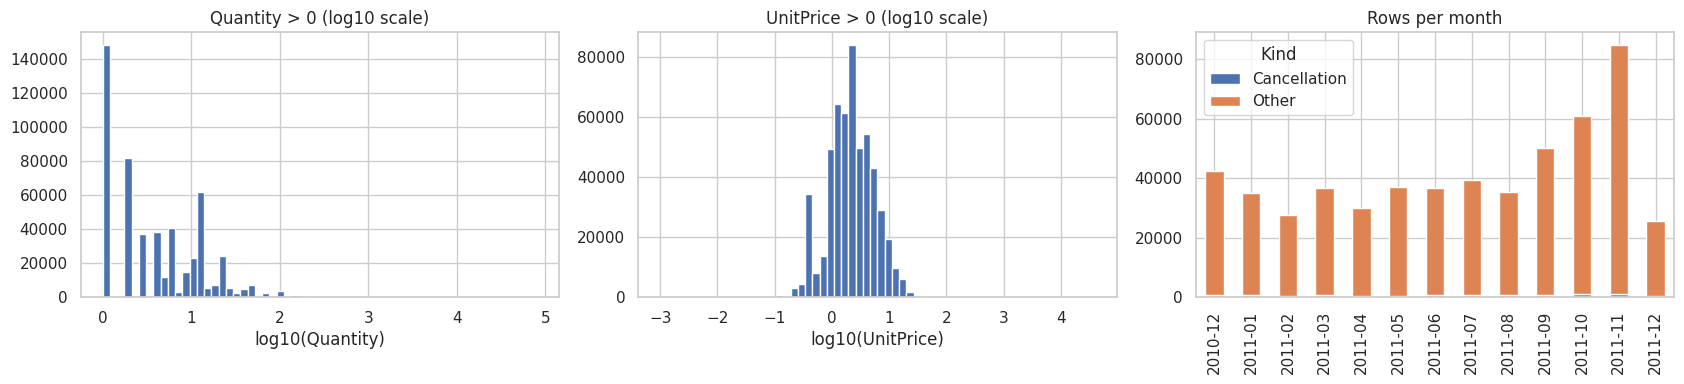

Observation window ends 09 Dec 2011; the final month is partial (9 of 31 days).


In [8]:
# 2b-4 | Quantities and prices   (READ-ONLY)
pcts = [.001, .01, .05, .25, .5, .75, .95, .99, .999]
print("Percentiles of raw Quantity and UnitPrice:")
display(dq[["Quantity", "UnitPrice"]].quantile(pcts).T)

sign_tbl = pd.DataFrame({
    "Quantity": [int((dq.Quantity < 0).sum()), int((dq.Quantity == 0).sum()), int((dq.Quantity > 0).sum())],
    "UnitPrice": [int((dq.UnitPrice < 0).sum()), int((dq.UnitPrice == 0).sum()), int((dq.UnitPrice > 0).sum())],
}, index=["negative", "zero", "positive"])
display(sign_tbl)

zero_p = dq.loc[dq.UnitPrice == 0]
print(f"\nZero-price rows: {len(zero_p):,} | missing CustomerID: {int(zero_p.CustomerID.isna().sum()):,} "
      f"| with a CustomerID: {int(zero_p.CustomerID.notna().sum()):,}")
display(zero_p["Description"].value_counts(dropna=False).head(8).to_frame("Rows"))
neg_p = dq.loc[dq.UnitPrice < 0]
print(f"Negative-price rows: {len(neg_p):,}")
if len(neg_p):
    display(neg_p.head(10))

thr = dq_u["Quantity"].abs().quantile(0.999)
ext = dq_u.loc[dq_u.Quantity.abs() >= thr].sort_values("Quantity", key=lambda s: s.abs(), ascending=False)
print(f"\nExtreme quantities (|Quantity| >= 99.9th percentile = {thr:,.0f}): {len(ext):,} rows. Top 10:")
display(ext.head(10)[["InvoiceNo", "StockCode", "Description", "Quantity", "UnitPrice", "CustomerID", "TotalPrice"]])

# --- Mirrored buy / cancel pairs: same customer, same item, same absolute quantity, both signs present
k = dq_u.dropna(subset=["CustomerID"]).copy()
k["AbsQty"] = k.Quantity.abs()
k["Sign"] = np.sign(k.Quantity)
sg = k.groupby(["CustomerID", "StockCode", "AbsQty"])["Sign"].agg(["min", "max", "size"])
pairs = sg.loc[(sg["min"] < 0) & (sg["max"] > 0)]
big_pairs = pairs.loc[pairs.index.get_level_values("AbsQty") >= thr]
print(f"\nREVIEW: mirrored buy/cancel pairs (same customer, item and quantity): {len(pairs):,} groups; "
      f"{len(big_pairs):,} of them at extreme quantity.")
print("Each such order is counted as a purchase invoice in Frequency and moves Recency even though it was reversed.")
print("This is a decision-log item. Section 3 keeps these rows, so compare the effect before deciding.")

lines = dq_u.loc[dq_u.TotalPrice > 0].nlargest(10, "TotalPrice")
print("\nLargest single line values (check whether they are real orders or administrative lines):")
display(lines[["InvoiceNo", "StockCode", "Description", "Quantity", "UnitPrice", "CustomerID", "TotalPrice"]])

# --- Plots
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
pos_q = dq.loc[dq.Quantity > 0, "Quantity"]; pos_p = dq.loc[dq.UnitPrice > 0, "UnitPrice"]
ax[0].hist(np.log10(pos_q), bins=60); ax[0].set_title("Quantity > 0 (log10 scale)"); ax[0].set_xlabel("log10(Quantity)")
ax[1].hist(np.log10(pos_p), bins=60); ax[1].set_title("UnitPrice > 0 (log10 scale)"); ax[1].set_xlabel("log10(UnitPrice)")
mon = dq.assign(Month=dq.InvoiceDate.dt.to_period("M").astype(str),
                Kind=np.where(dq.Invoice_type == "Cancellation (C)", "Cancellation", "Other"))
mon.groupby(["Month", "Kind"]).size().unstack(fill_value=0).plot(kind="bar", stacked=True, ax=ax[2])
ax[2].set_title("Rows per month"); ax[2].set_xlabel("")
plt.tight_layout(); plt.show()
last = dq.InvoiceDate.max()
print(f"Observation window ends {last:%d %b %Y}; the final month is partial ({last.day} of {last.days_in_month} days).")


In [9]:
# 2b-5 | Customer ID, country and internal-consistency checks   (READ-ONLY)
miss = dq.CustomerID.isna()
prof = pd.DataFrame({
    "Rows": [int(miss.sum()), int((~miss).sum())],
    "Cancellation_%": [(dq.Invoice_type[miss] == "Cancellation (C)").mean() * 100,
                       (dq.Invoice_type[~miss] == "Cancellation (C)").mean() * 100],
    "Qty<0_%": [(dq.Quantity[miss] < 0).mean() * 100, (dq.Quantity[~miss] < 0).mean() * 100],
    "Price=0_%": [(dq.UnitPrice[miss] == 0).mean() * 100, (dq.UnitPrice[~miss] == 0).mean() * 100],
    "Net_value": [dq.TotalPrice[miss].sum(), dq.TotalPrice[~miss].sum()],
}, index=["Missing CustomerID", "Has CustomerID"])
print(f"Rows without a CustomerID cannot be assigned to a customer: {miss.mean():.1%} of raw rows, "
      f"{dq.TotalPrice[miss].sum() / dq.TotalPrice.sum():.1%} of net transaction value.")
display(prof)

ctry = dq.groupby("Country").agg(Rows=("InvoiceNo", "size"), Missing_ID_share=("CustomerID", lambda s: s.isna().mean()),
                                 Customers=("CustomerID", "nunique")).sort_values("Rows", ascending=False)
print("\nTop countries (Country is not an RFM input; shown to see where missing IDs concentrate):")
display(ctry.head(8))

g = dq_u.groupby("InvoiceNo")
cons = pd.Series({
    "Invoices linked to more than one CustomerID": int((g.CustomerID.nunique() > 1).sum()),
    "Invoices linked to more than one InvoiceDate": int((g.InvoiceDate.nunique() > 1).sum()),
    "Invoices linked to more than one Country": int((g.Country.nunique() > 1).sum()),
    "Invoices mixing missing and present CustomerID": int((g.CustomerID.agg(lambda s: s.isna().any() and s.notna().any())).sum()),
    "Customers appearing in more than one Country": int((dq_u.dropna(subset=["CustomerID"]).groupby("CustomerID").Country.nunique() > 1).sum()),
}, name="Count").to_frame()
print("\nInternal consistency (0 is good):")
display(cons)


Rows without a CustomerID cannot be assigned to a customer: 24.9% of raw rows, 14.9% of net transaction value.


,Rows,Cancellation_%,Qty<0_%,Price=0_%,Net_value
Missing CustomerID,135080,0.2835,1.2726,1.8322,"1,447,682.1200"
Has CustomerID,406829,2.1889,2.1889,0.0098,"8,300,065.8140"



Top countries (Country is not an RFM input; shown to see where missing IDs concentrate):


,Rows,Missing_ID_share,Customers
Country,,,
United Kingdom,495478,0.2696,3950
Germany,9495,0.0000,95
France,8557,0.0077,87
EIRE,8196,0.0867,3
Spain,2533,0.0000,31
Netherlands,2371,0.0000,9
Belgium,2069,0.0000,25
Switzerland,2002,0.0624,21



Internal consistency (0 is good):


,Count
Invoices linked to more than one CustomerID,0
Invoices linked to more than one InvoiceDate,43
Invoices linked to more than one Country,0
Invoices mixing missing and present CustomerID,0
Customers appearing in more than one Country,8


In [10]:
# 2b-6 | Row-removal waterfall and data-quality report   (READ-ONLY)
# Re-implements the Section 3 rules in the same order, only to COUNT what they will remove.
cd_up = df_raw["StockCode"].astype(str).str.upper()
inv_c = df_raw["InvoiceNo"].astype(str).str.upper().str.startswith("C")
need = df_raw[["CustomerID", "InvoiceDate", "Quantity", "UnitPrice"]].isna().any(axis=1).to_numpy()

alive = np.ones(len(df_raw), dtype=bool)
seq = {}
def take(name, hit):
    global alive
    hit = np.asarray(hit) & alive
    seq[name] = int(hit.sum()); alive = alive & ~hit

take("Remove exact duplicate rows", dup_mask)
take("Remove missing IDs/dates/numeric values", need)
take("Remove administrative stock codes", cd_up.isin(ADMIN_CODES).to_numpy())
take("Remove non-positive UnitPrice", (df_raw["UnitPrice"] <= 0).to_numpy())
take("Remove non-cancellation rows with non-positive Quantity", (~inv_c & (df_raw["Quantity"] <= 0)).to_numpy())

surv = df_raw.loc[alive].copy()
surv_c = surv["InvoiceNo"].astype(str).str.upper().str.startswith("C")
surv["TotalPrice"] = surv.Quantity * surv.UnitPrice
buy_ids = surv.loc[~surv_c, "CustomerID"].unique()
net = surv.groupby("CustomerID")["TotalPrice"].sum().round(2).reindex(buy_ids)
dq_expected = {
    "rows_removed": seq, "rows_after": int(alive.sum()),
    "cancel_rows": int(surv_c.sum()), "cancel_invoices": int(surv.loc[surv_c, "InvoiceNo"].nunique()),
    "customers_after_cleaning": int(surv.CustomerID.nunique()),
    "customers_cancel_only": int(surv.CustomerID.nunique() - len(buy_ids)),
    "customers_nonpositive_net": int((net <= 0).sum()),
    "customers_modelled": int((net > 0).sum()),
}

indep = lambda m: int(np.asarray(m).sum())
rows = [
    ("Exact duplicate rows", indep(dup_mask), seq["Remove exact duplicate rows"], "REMOVE (Section 3, step 1)", "Inflate Frequency and Monetary"),
    ("Missing CustomerID / date / quantity / price", indep(need), seq["Remove missing IDs/dates/numeric values"], "REMOVE (step 2)", "Cannot be attributed to a customer"),
    ("Administrative stock codes (planned list)", indep(cd_up.isin(ADMIN_CODES)), seq["Remove administrative stock codes"], "REMOVE (step 3)", "Postage, fees, manual lines are not purchasing behaviour"),
    ("Non-positive UnitPrice", indep(df_raw["UnitPrice"] <= 0), seq["Remove non-positive UnitPrice"], "REMOVE (step 4)", "Zero/negative price carries no customer value"),
    ("Non-cancellation rows with Quantity <= 0", indep(~inv_c & (df_raw["Quantity"] <= 0)), seq["Remove non-cancellation rows with non-positive Quantity"], "REMOVE (step 5)", "Stock adjustments, not customer purchases"),
    ("Cancellation (C) rows", indep(inv_c), np.nan, "KEEP for Monetary only (net of returns)", "Excluded from Recency/Frequency"),
    ("Non-standard stock codes outside the planned list", int(len(review)), np.nan, "REVIEW", "See 2b-3 table B"),
    ("Non-upper-case descriptions", int(lower_desc.sum()), np.nan, "REVIEW", "See 2b-3 table C"),
    ("Mirrored buy/cancel pairs (groups)", int(len(pairs)), np.nan, "REVIEW", "See 2b-4"),
]
dq_report = pd.DataFrame(rows, columns=["Check", "Rows flagged (independent)", "Rows removed (in sequence)", "Proposed action", "Rationale"])
dq_report["Flagged_% of raw"] = dq_report["Rows flagged (independent)"] / n_raw * 100
display(dq_report)

wf = pd.DataFrame({"Step": ["Raw rows"] + list(seq) + ["Rows after cleaning (expected)"],
                   "Rows removed": [np.nan] + list(seq.values()) + [np.nan]})
wf["Rows remaining"] = [n_raw] + list(n_raw - np.cumsum(list(seq.values()))) + [dq_expected["rows_after"]]
print("\nExpected row-removal waterfall (rows can match several rules, so the sequential counts differ from the independent ones):")
display(wf)
print(f"Expected after cleaning: {dq_expected['rows_after']:,} rows | cancellation rows {dq_expected['cancel_rows']:,} "
      f"in {dq_expected['cancel_invoices']:,} invoices | customers {dq_expected['customers_after_cleaning']:,}")
print(f"Expected customer loss: cancel-only {dq_expected['customers_cancel_only']}, "
      f"non-positive net {dq_expected['customers_nonpositive_net']}, modelled {dq_expected['customers_modelled']:,}")

dq_report.to_csv("data_quality_report.csv", index=False)
wf.to_csv("data_quality_waterfall.csv", index=False)
code_tbl.reset_index().to_csv("data_quality_stockcode_audit.csv", index=False)
print("Saved: data_quality_report.csv, data_quality_waterfall.csv, data_quality_stockcode_audit.csv")


,Check,Rows flagged (independent),Rows removed (in sequence),Proposed action,Rationale,Flagged_% of raw
0,Exact duplicate rows,5268,"5,268.0000","REMOVE (Section 3, step 1)",Inflate Frequency and Monetary,0.9721
1,Missing CustomerID / date / quantity / price,135080,"135,037.0000",REMOVE (step 2),Cannot be attributed to a customer,24.9267
2,Administrative stock codes (planned list),2916,"1,915.0000",REMOVE (step 3),"Postage, fees, manual lines are not purchasing...",0.5381
3,Non-positive UnitPrice,2517,33.0000,REMOVE (step 4),Zero/negative price carries no customer value,0.4645
4,Non-cancellation rows with Quantity <= 0,1336,0.0000,REMOVE (step 5),"Stock adjustments, not customer purchases",0.2465
5,Cancellation (C) rows,9288,NaN,KEEP for Monetary only (net of returns),Excluded from Recency/Frequency,1.7139
6,Non-standard stock codes outside the planned list,21,NaN,REVIEW,See 2b-3 table B,0.0039
7,Non-upper-case descriptions,3027,NaN,REVIEW,See 2b-3 table C,0.5586
8,Mirrored buy/cancel pairs (groups),3080,NaN,REVIEW,See 2b-4,0.5684



Expected row-removal waterfall (rows can match several rules, so the sequential counts differ from the independent ones):


,Step,Rows removed,Rows remaining
0,Raw rows,NaN,541909
1,Remove exact duplicate rows,"5,268.0000",536641
2,Remove missing IDs/dates/numeric values,"135,037.0000",401604
3,Remove administrative stock codes,"1,915.0000",399689
4,Remove non-positive UnitPrice,33.0000,399656
5,Remove non-cancellation rows with non-positive...,0.0000,399656
6,Rows after cleaning (expected),NaN,399656


Expected after cleaning: 399,656 rows | cancellation rows 8,506 in 3,383 invoices | customers 4,362
Expected customer loss: cancel-only 28, non-positive net 14, modelled 4,320
Saved: data_quality_report.csv, data_quality_waterfall.csv, data_quality_stockcode_audit.csv


## 2c. Raw dataset profile: date range, calendar coverage, countries (read-only)

Key facts about the raw file for the report: the observation window, how well it covers the calendar, and where transactions and customers come from.

DATE RANGE


,Value
First transaction,2010-12-01 08:26:00
Last transaction,2011-12-09 12:50:00
Calendar span (days),374
Days with transactions,305
Days with no transactions,69
Coverage,81.6%



Gaps longer than 3 days with no transactions (holiday closures, data issues):


,Gap starts after,Next transaction,Days without transactions
20,2010-12-23,2011-01-04,11
113,2011-04-21,2011-04-26,4



Monthly activity (note a partial first/last month):


,Rows,Invoices,Customers,Trading_days
Month,,,,
2010-12,42481,2025,948,20
2011-01,35147,1476,783,24
2011-02,27707,1393,798,24
2011-03,36748,1983,1020,27
2011-04,29916,1744,899,21
2011-05,37030,2162,1079,25
2011-06,36874,2012,1051,26
2011-07,39518,1927,993,26
2011-08,35284,1737,980,26


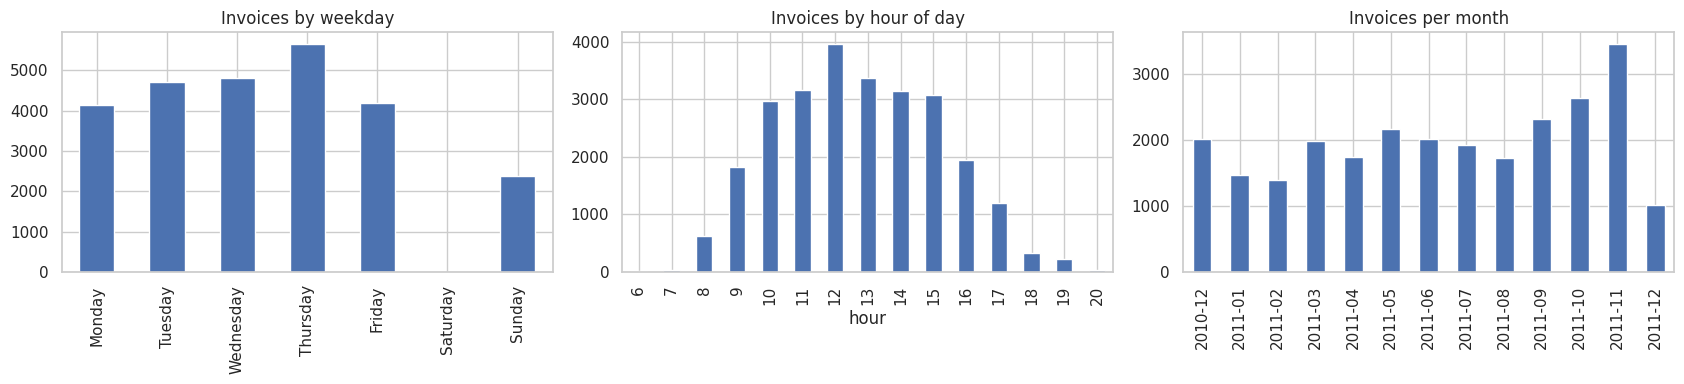


COUNTRIES (raw)
Distinct countries: 38 | top country: United Kingdom (91.4% of rows)


,Rows,Invoices,Customers_with_ID,Missing_ID_share,Net_value,Rows_%
Country,,,,,,
United Kingdom,495478,23494,3950,0.2696,"8,187,806.3640",91.4320
Germany,9495,603,95,0.0000,"221,698.2100",1.7521
France,8557,461,87,0.0077,"197,403.9000",1.5790
EIRE,8196,360,3,0.0867,"263,276.8200",1.5124
Spain,2533,105,31,0.0000,"54,774.5800",0.4674
Netherlands,2371,101,9,0.0000,"284,661.5400",0.4375
Belgium,2069,119,25,0.0000,"40,910.9600",0.3818
Switzerland,2002,74,21,0.0624,"56,385.3500",0.3694
Portugal,1519,71,19,0.0257,"29,367.0200",0.2803


Non-country labels present: ['Unspecified', 'European Community'] -> treat as 'unknown' in any country analysis.


In [19]:
# 2c | Raw dataset profile
d = df_raw.dropna(subset=["InvoiceDate"]).copy()
d["Day"] = d.InvoiceDate.dt.normalize()
first, last = d.InvoiceDate.min(), d.InvoiceDate.max()
span_days = (last.normalize() - first.normalize()).days + 1
trading_days = d.Day.nunique()

print("DATE RANGE")
display(pd.Series({
    "First transaction": str(first), "Last transaction": str(last),
    "Calendar span (days)": span_days, "Days with transactions": trading_days,
    "Days with no transactions": span_days - trading_days,
    "Coverage": f"{trading_days / span_days:.1%}",
}, name="Value").to_frame())

days = pd.Series(sorted(d.Day.unique()))
gap_days = days.diff().dt.days
gaps = pd.DataFrame({"Gap starts after": days.shift(1)[gap_days > 3].dt.date,
                     "Next transaction": days[gap_days > 3].dt.date,
                     "Days without transactions": (gap_days[gap_days > 3] - 1).astype(int)})
print("\nGaps longer than 3 days with no transactions (holiday closures, data issues):")
display(gaps if len(gaps) else "none")

order_days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
wd = d.groupby(d.InvoiceDate.dt.day_name())["InvoiceNo"].nunique().reindex(order_days).fillna(0).astype(int)
hr = d.groupby(d.InvoiceDate.dt.hour)["InvoiceNo"].nunique()
mon = d.assign(Month=d.InvoiceDate.dt.to_period("M")).groupby("Month").agg(
    Rows=("InvoiceNo", "size"), Invoices=("InvoiceNo", "nunique"),
    Customers=("CustomerID", "nunique"), Trading_days=("Day", "nunique"))
print("\nMonthly activity (note a partial first/last month):")
display(mon)

fig, ax = plt.subplots(1, 3, figsize=(17, 4))
wd.plot(kind="bar", ax=ax[0], title="Invoices by weekday"); ax[0].set_xlabel("")
hr.plot(kind="bar", ax=ax[1], title="Invoices by hour of day"); ax[1].set_xlabel("hour")
mon["Invoices"].plot(kind="bar", ax=ax[2], title="Invoices per month"); ax[2].set_xlabel("")
plt.tight_layout(); plt.show()

print("\nCOUNTRIES (raw)")
ctry_raw = df_raw.groupby("Country").agg(
    Rows=("InvoiceNo", "size"), Invoices=("InvoiceNo", "nunique"),
    Customers_with_ID=("CustomerID", "nunique"),
    Missing_ID_share=("CustomerID", lambda s: s.isna().mean()),
    Net_value=("UnitPrice", lambda s: float((s * df_raw.loc[s.index, "Quantity"]).sum()))
).sort_values("Rows", ascending=False)
ctry_raw["Rows_%"] = ctry_raw.Rows / ctry_raw.Rows.sum() * 100
print(f"Distinct countries: {len(ctry_raw)} | top country: {ctry_raw.index[0]} ({ctry_raw['Rows_%'].iloc[0]:.1f}% of rows)")
display(ctry_raw.head(15))
odd = ctry_raw.index.intersection(["Unspecified", "European Community"])
if len(odd):
    print("Non-country labels present:", list(odd), "-> treat as 'unknown' in any country analysis.")


## 3. Clean transactions

Cancellation invoices are retained for net Monetary calculation, but excluded from Recency and Frequency. This is an explicit analytical choice and should be explained in the report.

In [12]:
df = df_raw.copy()
cleaning_log = []

def log_step(step, before, after):
    cleaning_log.append({"Step": step, "Rows before": before, "Rows after": after,
                         "Rows removed": before - after})

n = len(df); df = df.drop_duplicates();                          log_step("Remove exact duplicate rows", n, len(df))
n = len(df); df = df.dropna(subset=["CustomerID", "InvoiceDate", "Quantity", "UnitPrice"]).copy(); log_step("Remove missing IDs/dates/numeric values", n, len(df))
df["CustomerID"] = df["CustomerID"].astype(int)

admin_codes = set(ADMIN_CODES)   # single source of truth: defined in Section 2b-1
n = len(df); df = df.loc[~df["StockCode"].astype(str).str.upper().isin(admin_codes)].copy()
log_step("Remove administrative stock codes", n, len(df))

n = len(df); df = df.loc[df["UnitPrice"] > 0].copy();            log_step("Remove non-positive UnitPrice", n, len(df))

df["InvoiceNo"] = df["InvoiceNo"].astype(str)
df["IsCancellation"] = df["InvoiceNo"].str.upper().str.startswith("C")

n = len(df)
df = df.loc[df["IsCancellation"] | (df["Quantity"] > 0)].copy()
log_step("Remove non-cancellation rows with non-positive Quantity", n, len(df))

df["TotalPrice"] = df["Quantity"] * df["UnitPrice"]
cleaning_log_df = pd.DataFrame(cleaning_log)
display(cleaning_log_df)
print("Cancellation rows:", int(df["IsCancellation"].sum()),
      "| invoices:", df.loc[df["IsCancellation"], "InvoiceNo"].nunique())

,Step,Rows before,Rows after,Rows removed
0,Remove exact duplicate rows,541909,536641,5268
1,Remove missing IDs/dates/numeric values,536641,401604,135037
2,Remove administrative stock codes,401604,399689,1915
3,Remove non-positive UnitPrice,399689,399656,33
4,Remove non-cancellation rows with non-positive...,399656,399656,0


Cancellation rows: 8506 | invoices: 3383


In [13]:
# Reconciliation: the data-quality audit (2b-6) must predict exactly what Section 3 removed
exp = list(dq_expected["rows_removed"].values())
chk = cleaning_log_df[["Step", "Rows removed"]].copy()
chk["Expected (audit 2b-6)"] = exp
chk["Match"] = chk["Rows removed"].to_numpy() == chk["Expected (audit 2b-6)"].to_numpy()
display(chk)
assert chk["Match"].all(), "Cleaning does not match the data-quality audit; the rules in 2b-6 and Section 3 have diverged."
assert len(df) == dq_expected["rows_after"], "Rows after cleaning differ from the audit's expectation."
assert int(df["IsCancellation"].sum()) == dq_expected["cancel_rows"], "Cancellation row count differs from the audit."
print("OK: audit and cleaning agree on every step.")


,Step,Rows removed,Expected (audit 2b-6),Match
0,Remove exact duplicate rows,5268,5268,True
1,Remove missing IDs/dates/numeric values,135037,135037,True
2,Remove administrative stock codes,1915,1915,True
3,Remove non-positive UnitPrice,33,33,True
4,Remove non-cancellation rows with non-positive...,0,0,True


OK: audit and cleaning agree on every step.


## 4. Build customer-level RFM features

Customers with non-positive net spend are excluded from the clustering dataset. The customer-loss table documents this choice.

In [15]:
snapshot_date = df["InvoiceDate"].max().normalize() + pd.Timedelta(days=1)
print("Snapshot date:", snapshot_date)

customers_clean = df["CustomerID"].nunique()
rfm_all = build_rfm(df, snapshot_date)
cancel_only = customers_clean - len(rfm_all)

# round net spend to pence so floating-point leftovers (e.g. 1e-12) count as zero
rfm_all["Monetary"] = rfm_all["Monetary"].round(2)

rfm = rfm_all.loc[rfm_all["Monetary"] > 0].reset_index(drop=True)
non_positive = len(rfm_all) - len(rfm)

customer_loss_log = pd.DataFrame({
    "Stage": ["Customers after row cleaning", "Dropped: cancellations only (no purchase invoice)",
              "Dropped: non-positive net Monetary", "Customers modelled"],
    "Count": [customers_clean, cancel_only, non_positive, len(rfm)]
})
display(customer_loss_log)

rfm_features = ["Recency", "Frequency", "Monetary"]
display(rfm[rfm_features].describe().T)

print("Five smallest Monetary values kept:")
display(rfm.nsmallest(5, "Monetary"))
assert not rfm.empty, "No customers remain after RFM construction and filtering."
assert rfm["CustomerID"].is_unique, "RFM must contain exactly one row per customer."
assert rfm[rfm_features].notna().all().all(), "RFM features contain missing values."
assert (rfm["Recency"] >= 0).all(), "Recency should be non-negative for the chosen snapshot."
assert (rfm["Frequency"] >= 1).all(), "Frequency should be at least one purchase invoice."
assert (rfm["Monetary"] >= 0.01).all(), "Near-zero/non-positive Monetary customers remain."

Snapshot date: 2011-12-10 00:00:00


,Stage,Count
0,Customers after row cleaning,4362
1,Dropped: cancellations only (no purchase invoice),28
2,Dropped: non-positive net Monetary,14
3,Customers modelled,4320


,count,mean,std,min,25%,50%,75%,max
Recency,"4,320.0000",93.0725,100.1189,1.0000,18.0000,51.0000,143.0000,374.0000
Frequency,"4,320.0000",4.2560,7.6453,1.0000,1.0000,2.0000,5.0000,206.0000
Monetary,"4,320.0000","1,914.2679","8,303.7846",2.9000,299.0450,650.4200,"1,610.4575","278,778.0200"


Five smallest Monetary values kept:


,CustomerID,Recency,Frequency,Monetary
2997,16446,1,2,2.9000
3205,16738,298,1,3.7500
3003,16454,65,1,5.9000
4162,18072,186,1,12.2400
4082,17956,250,1,12.7500


In [16]:
# Reconciliation: customer-level losses must match the audit's prediction
got = {"customers_after_cleaning": int(customers_clean), "customers_cancel_only": int(cancel_only),
       "customers_nonpositive_net": int(non_positive), "customers_modelled": int(len(rfm))}
for key, val in got.items():
    assert val == dq_expected[key], f"{key}: notebook={val} vs audit={dq_expected[key]}"
print("OK: customer-loss table matches the audit:", got)


OK: customer-loss table matches the audit: {'customers_after_cleaning': 4362, 'customers_cancel_only': 28, 'customers_nonpositive_net': 14, 'customers_modelled': 4320}


## 5. Explore RFM distributions

,raw skew
Recency,1.2458
Frequency,11.9361
Monetary,21.5440


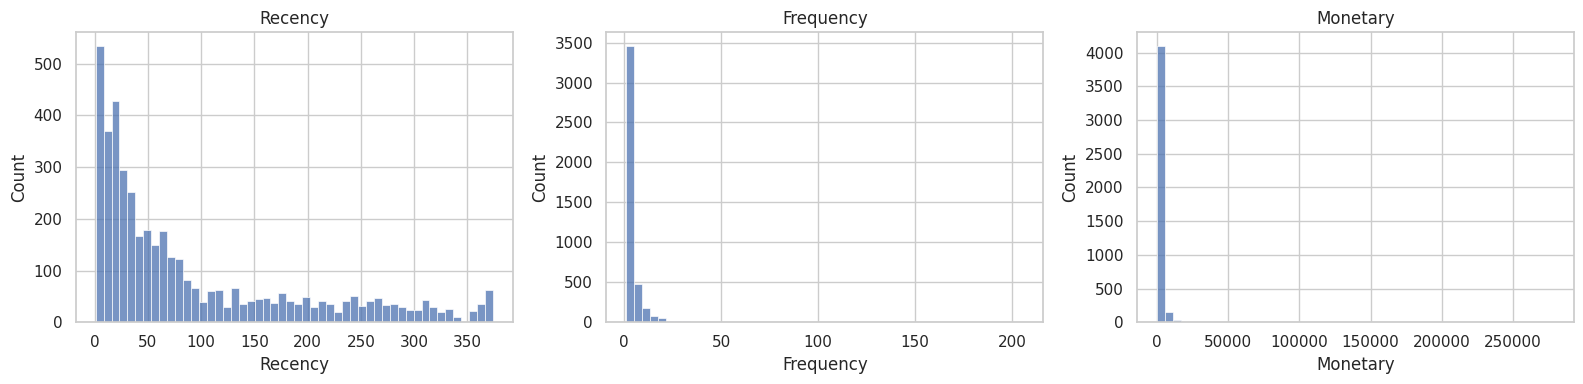

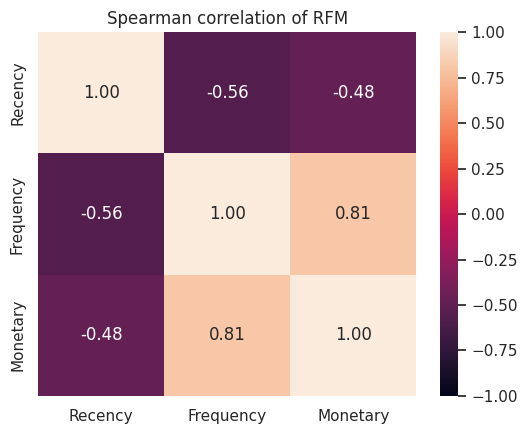

In [17]:
display(rfm[rfm_features].skew().to_frame("raw skew"))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, rfm_features):
    sns.histplot(rfm[col], bins=50, ax=ax); ax.set_title(col)
plt.tight_layout(); plt.show()

# Spearman is unchanged by log transforms, so this is valid for raw and log features
plt.figure(figsize=(5.5, 4.5))
sns.heatmap(rfm[rfm_features].corr(method="spearman"), annot=True, fmt=".2f", vmin=-1, vmax=1)
plt.title("Spearman correlation of RFM"); plt.tight_layout(); plt.show()

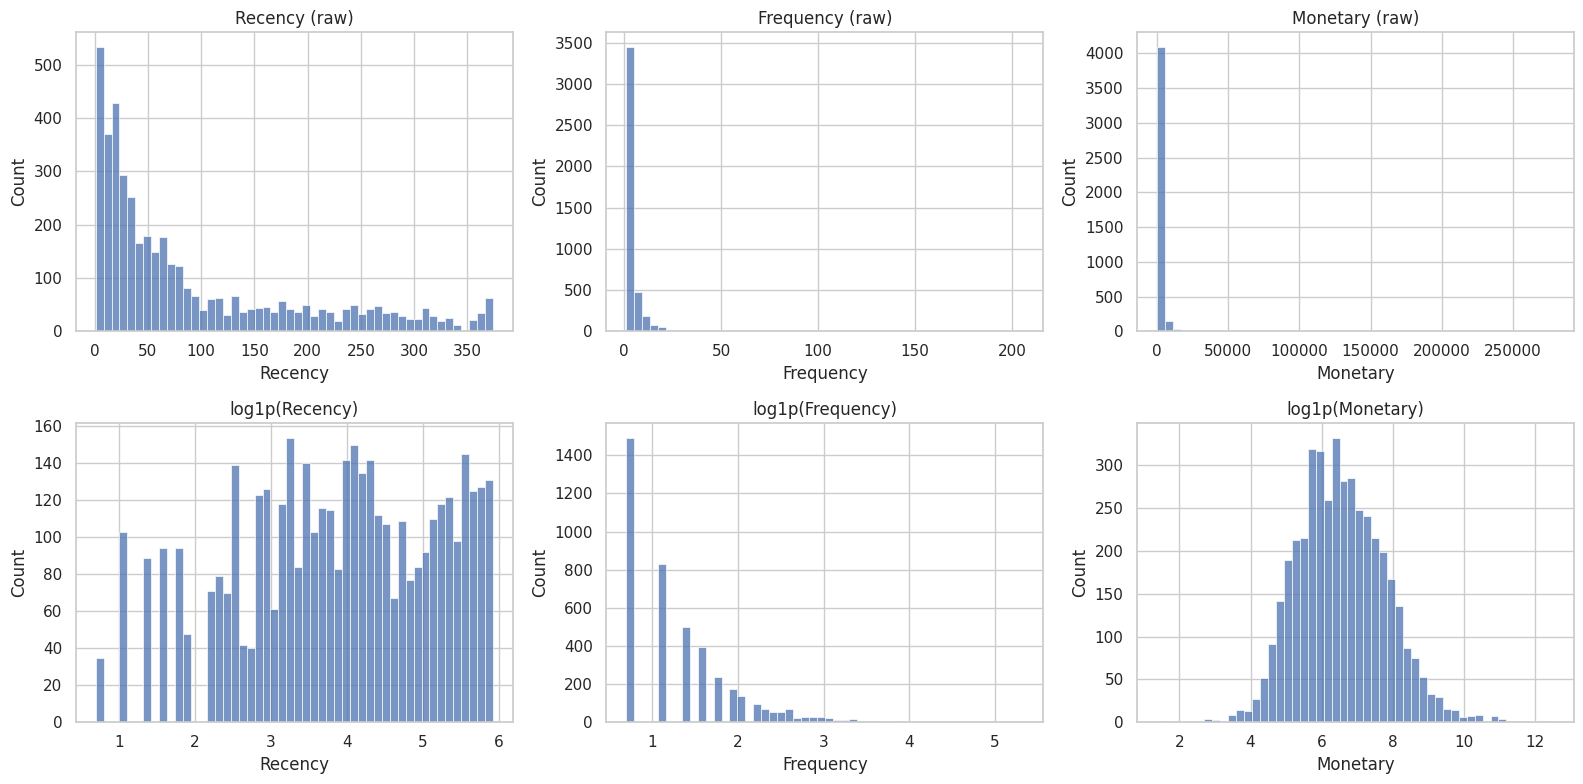

In [18]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for j, col in enumerate(rfm_features):
    sns.histplot(rfm[col], bins=50, ax=axes[0, j]); axes[0, j].set_title(f"{col} (raw)")
    sns.histplot(np.log1p(rfm[col]), bins=50, ax=axes[1, j]); axes[1, j].set_title(f"log1p({col})")
plt.tight_layout(); plt.show()

## 6. Split data and fit preprocessing on training data only

Clipping thresholds and scaling parameters are learned on the training partition and applied unchanged to the validation partition. Because the validation scores are reviewed when selecting K, this partition is a **validation set**, not an untouched final test set.

In [ ]:
F = np.log1p(rfm[rfm_features].to_numpy(dtype=float))   # log only; clip and scale happen in the pipeline
print("Log skew:", dict(zip(rfm_features, np.round(pd.DataFrame(F).skew().values, 3))))

idx_train, idx_test = train_test_split(np.arange(len(F)), test_size=0.30, random_state=RANDOM_STATE)
F_train, F_test = F[idx_train], F[idx_test]

prep_tt = make_preprocessor().fit(F_train)           # learns clip limits and mean/std from train only
X_train = prep_tt.transform(F_train)
X_test = prep_tt.transform(F_test)                   # transform only, never fit

print("Train:", X_train.shape, "| Test:", X_test.shape)
if "clip" in prep_tt.named_steps:
    hi = prep_tt.named_steps["clip"].hi_
    for c, v in hi.items():
        print(f"Clip cap {rfm_features[c]}: {np.expm1(v):,.1f} (original units)")

Log skew: {'Recency': np.float64(-0.324), 'Frequency': np.float64(1.211), 'Monetary': np.float64(0.365)}
Train: (3024, 3) | Test: (1296, 3)
Clip cap Frequency: 40.8 (original units)
Clip cap Monetary: 39,229.4 (original units)


## 7. Select K-Means candidate values of k

Compare the elbow curve, silhouette score, and Davies–Bouldin index on both partitions. The 70/30 holdout is used for model selection, so these are validation estimates rather than a final independent test. Higher silhouette and lower Davies–Bouldin are generally preferable, but neither metric alone determines business usefulness.

,k,inertia,sil_train,sil_test,db_train,db_test
0,2,"4,390.7686",0.4400,0.4171,0.8751,0.9164
1,3,"3,284.1706",0.3336,0.3347,1.0577,1.0403
2,4,"2,640.3342",0.3350,0.3353,1.0123,1.0213
3,5,"2,201.9402",0.3171,0.3183,0.9912,0.9904
4,6,"1,896.3944",0.3174,0.3090,1.0124,1.0117
5,7,"1,692.2129",0.3125,0.3045,0.9696,0.9811
6,8,"1,547.7164",0.3048,0.2965,0.9893,0.9971


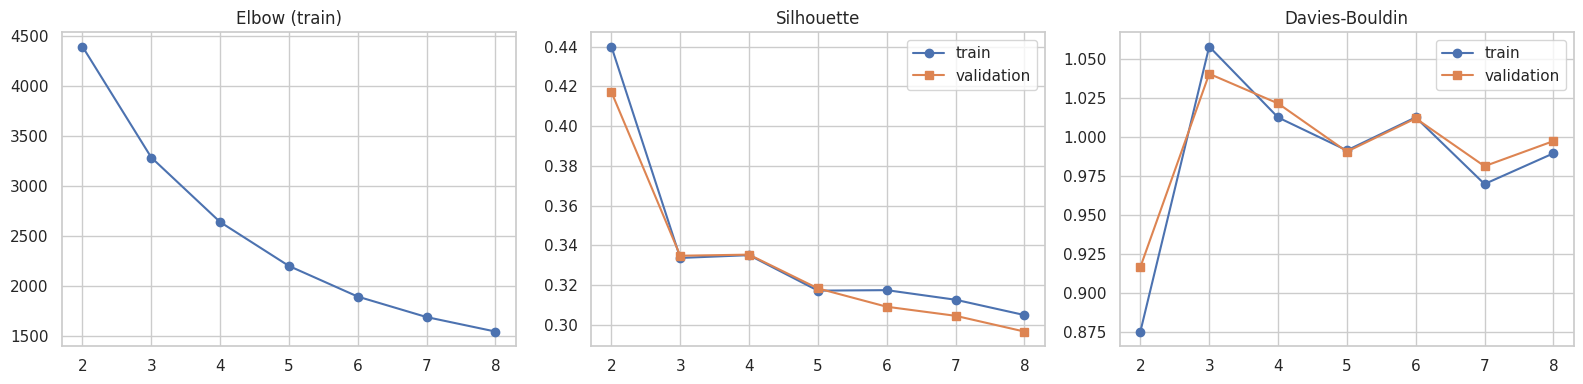

In [ ]:
rows = []
for k in K_RANGE:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=20).fit(X_train)
    tr, te = metric_row(X_train, km.labels_), metric_row(X_test, km.predict(X_test))
    rows.append({"k": k, "inertia": km.inertia_,
                 "sil_train": tr["sil"], "sil_test": te["sil"],
                 "db_train": tr["db"], "db_test": te["db"]})
km_df = pd.DataFrame(rows)
display(km_df)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].plot(km_df.k, km_df.inertia, marker="o"); axes[0].set_title("Elbow (train)")
axes[1].plot(km_df.k, km_df.sil_train, marker="o", label="train")
axes[1].plot(km_df.k, km_df.sil_test, marker="s", label="validation"); axes[1].set_title("Silhouette"); axes[1].legend()
axes[2].plot(km_df.k, km_df.db_train, marker="o", label="train")
axes[2].plot(km_df.k, km_df.db_test, marker="s", label="validation"); axes[2].set_title("Davies-Bouldin"); axes[2].legend()
plt.tight_layout(); plt.show()

## 8. Compare hierarchical clustering

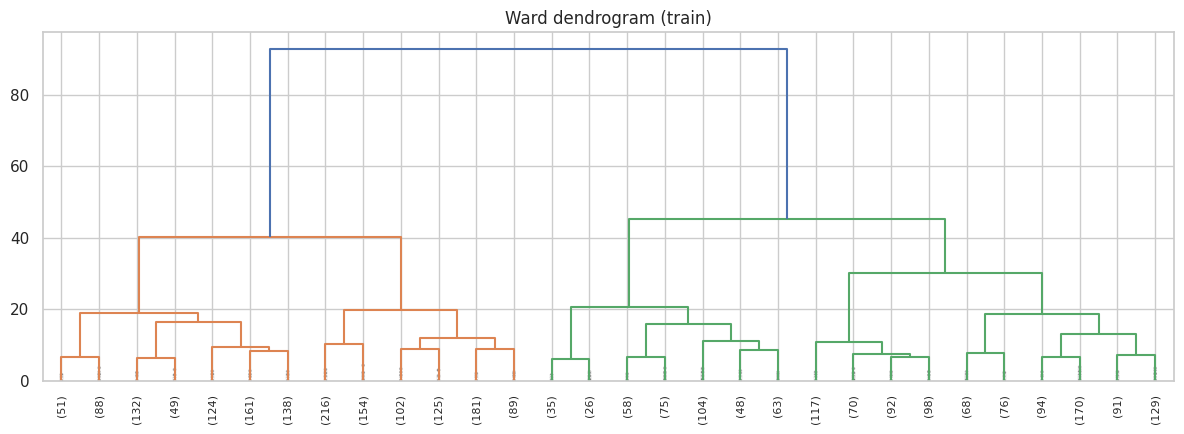

,k,sil_train_ward,sil_train_nc,sil_test_nc,db_train_ward,db_train_nc,db_test_nc
0,2,0.3923,0.4311,0.4103,0.9483,0.8880,0.9293
1,3,0.3090,0.3500,0.3467,1.1029,1.0152,1.0058
2,4,0.2781,0.3065,0.3108,1.1242,1.0817,1.0817
3,5,0.2658,0.3128,0.3141,1.1060,1.0209,1.0149
4,6,0.2614,0.3076,0.3071,1.0921,1.0299,1.0162
5,7,0.2192,0.2691,0.2644,1.1100,1.0379,1.0376
6,8,0.2137,0.2637,0.2581,1.1179,1.0690,1.0807


In [ ]:
Z = linkage(X_train, method="ward")
plt.figure(figsize=(12, 4.5))
dendrogram(Z, truncate_mode="lastp", p=30, leaf_rotation=90, leaf_font_size=8, show_contracted=True)
plt.title("Ward dendrogram (train)"); plt.tight_layout(); plt.show()

rows = []
for k in K_RANGE:
    ward = AgglomerativeClustering(n_clusters=k, linkage="ward").fit(X_train)
    nc = NearestCentroid().fit(X_train, ward.labels_)
    train_nc = nc.predict(X_train)      # train re-labelled by the SAME rule used for test
    test_nc = nc.predict(X_test)

    tr = metric_row(X_train, ward.labels_)     # Ward's own labels
    tr_nc = metric_row(X_train, train_nc)      # like-for-like with test
    te = metric_row(X_test, test_nc)
    rows.append({"k": k,
                 "sil_train_ward": tr["sil"], "sil_train_nc": tr_nc["sil"], "sil_test_nc": te["sil"],
                 "db_train_ward": tr["db"], "db_train_nc": tr_nc["db"], "db_test_nc": te["db"]})
display(pd.DataFrame(rows))

## 9. Explore DBSCAN

DBSCAN can mark observations as noise and may find very small clusters. Its silhouette is computed only on non-noise points and must not be compared naively with other models.

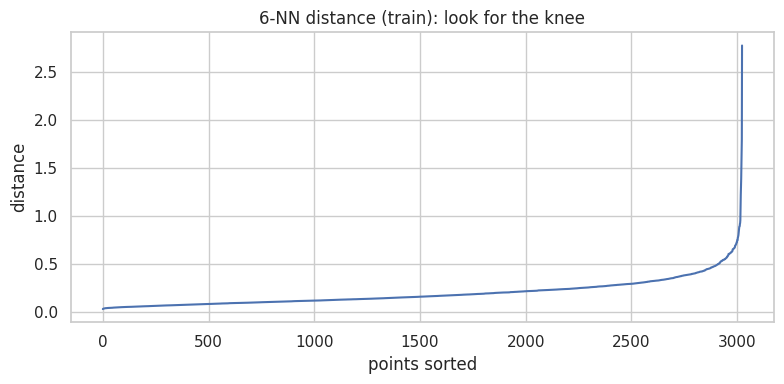

,eps,n_clusters,noise_rate,sil_non_noise_only
0,0.3000,9,0.0866,0.0875
1,0.4000,4,0.0321,0.1474
2,0.5000,3,0.0129,0.2530
3,0.6000,1,0.0056,NaN
4,0.7000,1,0.0030,NaN
5,0.8000,1,0.0026,NaN


Note: DBSCAN silhouette excludes noise, so it is not directly comparable with the other methods.


In [ ]:
MIN_SAMPLES = 6   # about 2 x number of features
nn = NearestNeighbors(n_neighbors=MIN_SAMPLES + 1).fit(X_train)
# Include the point itself (distance 0), so the last distance is the MIN_SAMPLES-th neighbour distance.
kd = np.sort(nn.kneighbors(X_train)[0][:, -1])

plt.figure(figsize=(8, 4))
plt.plot(kd); plt.title(f"{MIN_SAMPLES}-NN distance (train): look for the knee")
plt.ylabel("distance"); plt.xlabel("points sorted"); plt.tight_layout(); plt.show()

rows = []
for eps in [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]:
    lab = DBSCAN(eps=eps, min_samples=MIN_SAMPLES).fit_predict(X_train)
    mask = lab != -1
    n_cl = len(set(lab[mask]))
    rows.append({"eps": eps, "n_clusters": n_cl, "noise_rate": (~mask).mean(),
                 "sil_non_noise_only": silhouette_score(X_train[mask], lab[mask]) if n_cl >= 2 else np.nan})
display(pd.DataFrame(rows))
print("Note: DBSCAN silhouette excludes noise, so it is not directly comparable with the other methods.")

In [ ]:
lab = DBSCAN(eps=0.5, min_samples=MIN_SAMPLES).fit_predict(X_train)
print(pd.Series(lab).value_counts().sort_index())

-1      39
 0    1929
 1    1046
 2      10
Name: count, dtype: int64


In [ ]:
lab = DBSCAN(eps=0.5, min_samples=MIN_SAMPLES).fit_predict(X_train)
km2 = KMeans(n_clusters=2, random_state=RANDOM_STATE, n_init=20).fit(X_train)
print(pd.crosstab(lab, km2.labels_, rownames=["DBSCAN"], colnames=["KMeans k=2"]))

tr = rfm.iloc[idx_train].copy()
tr["dbscan"] = lab
cluster_sizes = tr.loc[tr.dbscan != -1, "dbscan"].value_counts().sort_values()
small_ids = cluster_sizes[cluster_sizes < 25].index
print("Small DBSCAN clusters (<25 customers):", list(small_ids))
for cluster_id in small_ids:
    print(f"\nDBSCAN cluster {cluster_id} profile (n={(tr.dbscan == cluster_id).sum()}):")
    display(tr.loc[tr.dbscan == cluster_id, rfm_features].describe().T)
print("Noise rate:", f"{(tr.dbscan == -1).mean():.1%}")

KMeans k=2     0     1
DBSCAN                
-1            33     6
 0          1117   812
 1             0  1046
 2            10     0
Small DBSCAN clusters (<25 customers): [2]

DBSCAN cluster 2 profile (n=10):


,count,mean,std,min,25%,50%,75%,max
Recency,10.0000,2.7000,1.3375,1.0000,2.0000,2.5000,3.7500,5.0000
Frequency,10.0000,72.9000,49.4873,28.0000,47.2500,58.5000,86.2500,198.0000
Monetary,10.0000,"106,192.4860","90,215.7456","33,453.4500","55,018.2875","62,602.1550","118,610.7300","278,778.0200"


Noise rate: 1.3%


## 10. Explore Gaussian Mixture Models

Review convergence, held-out log-likelihood, component weights, and covariance eigenvalues together. BIC/AIC values are for the same training data and should not be compared across different datasets.

,k,bic_train,aic_train,loglik_train,loglik_test,min_weight,min_cov_eig,converged
0,2,"16,338.7005","16,224.4281",-2.6763,-2.7024,0.3411,0.0010,True
1,3,"15,819.8558","15,645.4400",-2.5773,-2.6105,0.2522,0.0010,True
2,4,"13,761.3325","13,526.7734",-2.2237,-2.2357,0.1847,0.0010,True
3,5,"13,656.1200","13,361.4175",-2.1930,-2.2057,0.0905,0.0010,True
4,6,"13,416.3552","13,061.5094",-2.1401,-2.1336,0.0952,0.0010,True
5,7,"13,361.4776","12,946.4885",-2.1178,-2.1122,0.0521,0.0010,True
6,8,"11,696.0836","11,220.9511",-1.8292,-1.8248,0.0577,0.0010,True


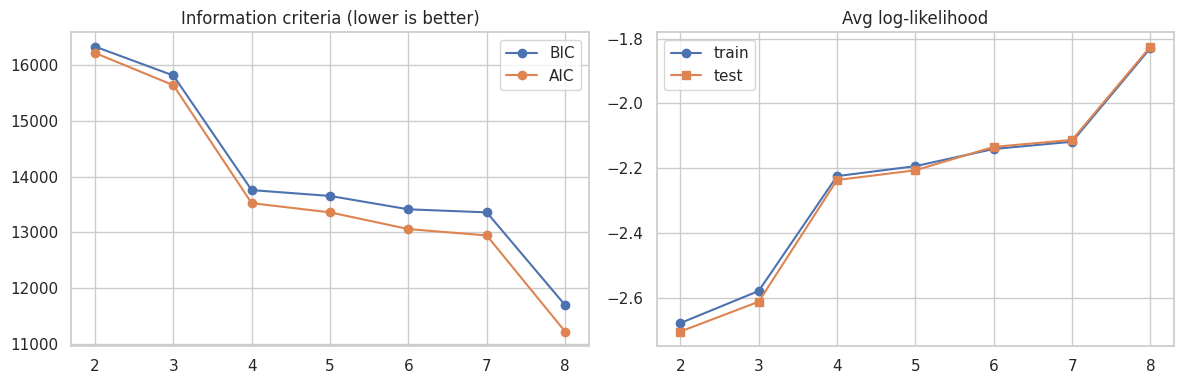

In [ ]:
rows = []
for k in K_RANGE:
    g = GaussianMixture(n_components=k, covariance_type="full", reg_covar=1e-3,
                        n_init=5, random_state=RANDOM_STATE).fit(X_train)
    rows.append({"k": k, "bic_train": g.bic(X_train), "aic_train": g.aic(X_train),
                 "loglik_train": g.score(X_train), "loglik_test": g.score(X_test),
                 "min_weight": g.weights_.min(),
                 "min_cov_eig": min(np.linalg.eigvalsh(c).min() for c in g.covariances_),
                 "converged": g.converged_})
gmm_df = pd.DataFrame(rows)
display(gmm_df)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(gmm_df.k, gmm_df.bic_train, marker="o", label="BIC")
axes[0].plot(gmm_df.k, gmm_df.aic_train, marker="o", label="AIC"); axes[0].legend(); axes[0].set_title("Information criteria (lower is better)")
axes[1].plot(gmm_df.k, gmm_df.loglik_train, marker="o", label="train")
axes[1].plot(gmm_df.k, gmm_df.loglik_test, marker="s", label="test"); axes[1].legend(); axes[1].set_title("Avg log-likelihood")
plt.tight_layout(); plt.show()

In [ ]:
print("Share of train with Frequency == 1:", (rfm.iloc[idx_train]["Frequency"] == 1).mean())

for k in [2, 3]:
    g = GaussianMixture(n_components=k, covariance_type="full", reg_covar=1e-3,
                        n_init=5, random_state=RANDOM_STATE).fit(X_train)
    print(f"\nk={k}")
    for i, (w, c) in enumerate(zip(g.weights_, g.covariances_)):
        print(f"  comp {i}: weight={w:.3f}, covariance eigenvalues={np.round(np.linalg.eigvalsh(c), 4)}")

Share of train with Frequency == 1: 0.3472222222222222

k=2
  comp 0: weight=0.659, covariance eigenvalues=[0.1668 0.5674 1.7136]
  comp 1: weight=0.341, covariance eigenvalues=[0.001  0.3873 0.6302]

k=3
  comp 0: weight=0.345, covariance eigenvalues=[0.001  0.3862 0.6315]
  comp 1: weight=0.252, covariance eigenvalues=[0.1241 0.552  1.3505]
  comp 2: weight=0.403, covariance eigenvalues=[0.1076 0.4945 0.7818]


## 11. Compare algorithms under a common train/validation split

Ward clustering is converted to a nearest-centroid prediction rule for held-out assignment; this is an approximation, not the same as a native hierarchical prediction method. GMM uses hard component assignments. Compare the algorithms cautiously because their assignment mechanisms differ.

In [ ]:
def row(model, k, X_tr, lab_tr, X_te, lab_te):
    tr, te = metric_row(X_tr, lab_tr), metric_row(X_te, lab_te)
    return {"Model": model, "k": k,
            "sil_train": tr["sil"], "sil_test": te["sil"],
            "db_train": tr["db"], "db_test": te["db"]}

rows = []
for k in K_COMPARE:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=20).fit(X_train)
    rows.append(row("K-Means", k, X_train, km.labels_, X_test, km.predict(X_test)))

    ward = AgglomerativeClustering(n_clusters=k, linkage="ward").fit(X_train)
    nc = NearestCentroid().fit(X_train, ward.labels_)
    rows.append(row("Ward (nearest-centroid rule)", k, X_train, nc.predict(X_train), X_test, nc.predict(X_test)))

    g = GaussianMixture(n_components=k, covariance_type="full", reg_covar=1e-3,
                        n_init=5, random_state=RANDOM_STATE).fit(X_train)
    rows.append(row("GMM (hard assignment)", k, X_train, g.predict(X_train), X_test, g.predict(X_test)))

model_comparison = pd.DataFrame(rows).sort_values(["k", "sil_test"], ascending=[True, False])
display(model_comparison)

,Model,k,sil_train,sil_test,db_train,db_test
0,K-Means,2,0.4400,0.4171,0.8751,0.9164
1,Ward (nearest-centroid rule),2,0.4311,0.4103,0.8880,0.9293
2,GMM (hard assignment),2,0.2892,0.2886,1.0557,1.0882
4,Ward (nearest-centroid rule),3,0.3500,0.3467,1.0152,1.0058
3,K-Means,3,0.3336,0.3347,1.0577,1.0403
5,GMM (hard assignment),3,0.2609,0.2474,1.2308,1.2534
6,K-Means,4,0.3350,0.3353,1.0123,1.0213
7,Ward (nearest-centroid rule),4,0.3065,0.3108,1.0817,1.0817
8,GMM (hard assignment),4,0.1760,0.1596,1.7344,1.7530


## 12. Evaluate prediction strength

Prediction strength estimates whether clusters discovered in one half are preserved in the other. It measures structural reproducibility, not marketing effectiveness. This implementation fits preprocessing separately within each half to avoid fitting transformations on the other half.

In [ ]:
def prediction_strength_once(F_all, k, seed):
    F_a, F_b = train_test_split(F_all, test_size=0.5, random_state=seed)
    prep_a = make_preprocessor().fit(F_a)
    prep_b = make_preprocessor().fit(F_b)

    km_a = KMeans(n_clusters=k, random_state=seed, n_init=10).fit(prep_a.transform(F_a))
    km_b = KMeans(n_clusters=k, random_state=seed + 10_000, n_init=10).fit(prep_b.transform(F_b))

    pred_b = km_a.predict(prep_a.transform(F_b))     # half A's model applied to half B
    strengths = []
    for c in np.unique(km_b.labels_):
        members = pred_b[km_b.labels_ == c]
        n = len(members)
        if n < 2:
            continue
        counts = np.bincount(members)
        same_pairs = (counts * (counts - 1) / 2).sum()
        strengths.append(same_pairs / (n * (n - 1) / 2))
    # A split with no cluster containing at least two members is not evaluable.
    return min(strengths) if strengths else np.nan

rows = []
for k in K_RANGE:
    scores = np.array([prediction_strength_once(F, k, RANDOM_STATE + r) for r in range(15)], dtype=float)
    scores = scores[np.isfinite(scores)]
    rows.append({"k": k, "ps_mean": np.mean(scores) if len(scores) else np.nan,
                 "ps_std": np.std(scores) if len(scores) else np.nan,
                 "ps_min": np.min(scores) if len(scores) else np.nan,
                 "ps_max": np.max(scores) if len(scores) else np.nan,
                 "valid_splits": len(scores)})
ps_df = pd.DataFrame(rows)
display(ps_df)

,k,ps_mean,ps_std,ps_min,ps_max,valid_splits
0,2,0.9566,0.0260,0.9027,0.9970,15
1,3,0.8676,0.0581,0.7352,0.9647,15
2,4,0.7531,0.1110,0.4991,0.9088,15
3,5,0.5697,0.0875,0.4364,0.7466,15
4,6,0.5629,0.0909,0.3877,0.6952,15
5,7,0.5471,0.1016,0.3636,0.7217,15
6,8,0.4668,0.0550,0.4109,0.6007,15


## 13. Review the evidence and decide K yourself

This notebook does **not** automatically choose the final number of clusters. Review the candidate metrics, prediction strength, bootstrap stability, segment profiles, and future-behaviour check. K=2 may score best statistically, while K=3 may be more actionable for the business; that trade-off must be explicitly justified. Since this validation partition informed K selection, do not describe its score as an independent final test result.

,k,sil_train,sil_test,db_train,db_test,ps_mean,ps_std,ps_min,ps_max,valid_splits,ps_pass
0,2,0.4400,0.4171,0.8751,0.9164,0.9566,0.0260,0.9027,0.9970,15,True
1,3,0.3336,0.3347,1.0577,1.0403,0.8676,0.0581,0.7352,0.9647,15,True
2,4,0.3350,0.3353,1.0123,1.0213,0.7531,0.1110,0.4991,0.9088,15,False
3,5,0.3171,0.3183,0.9912,0.9904,0.5697,0.0875,0.4364,0.7466,15,False
4,6,0.3174,0.3090,1.0124,1.0117,0.5629,0.0909,0.3877,0.6952,15,False
5,7,0.3125,0.3045,0.9696,0.9811,0.5471,0.1016,0.3636,0.7217,15,False
6,8,0.3048,0.2965,0.9893,0.9971,0.4668,0.0550,0.4109,0.6007,15,False


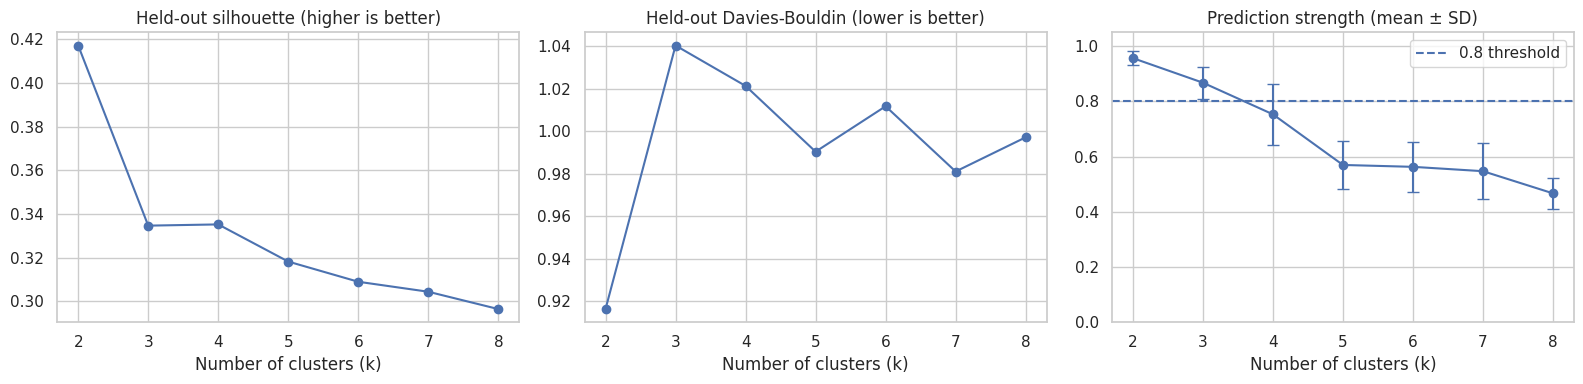

Diagnostic suggestion only: 2
You will choose FINAL_K manually in Section 14.


In [ ]:
sel = km_df.merge(ps_df, on="k")
sel["ps_pass"] = sel["ps_mean"] >= PS_THRESHOLD
display(sel[["k", "sil_train", "sil_test", "db_train", "db_test",
             "ps_mean", "ps_std", "ps_min", "ps_max", "valid_splits", "ps_pass"]])

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].plot(sel.k, sel.sil_test, marker="o")
axes[0].set_title("Held-out silhouette (higher is better)")
axes[1].plot(sel.k, sel.db_test, marker="o")
axes[1].set_title("Held-out Davies-Bouldin (lower is better)")
axes[2].errorbar(sel.k, sel.ps_mean, yerr=sel.ps_std, marker="o", capsize=4)
axes[2].axhline(PS_THRESHOLD, linestyle="--", label=f"{PS_THRESHOLD} threshold")
axes[2].set_ylim(0, 1.05)
axes[2].set_title("Prediction strength (mean ± SD)")
axes[2].legend()
for ax in axes:
    ax.set_xlabel("Number of clusters (k)")
plt.tight_layout()
plt.show()

eligible = sel.loc[sel["ps_pass"] & sel["sil_test"].notna()]
recommended_k = None
if eligible.empty:
    print("No candidate passes the mean prediction-strength threshold.")
else:
    recommended_k = int(eligible.loc[eligible["sil_test"].idxmax(), "k"])
    print("Diagnostic suggestion only:", recommended_k)
print("You will choose FINAL_K manually in Section 14.")


## 14. Choose K manually, then fit the final model

Review the evaluation tables above and set `FINAL_K` to the chosen value. The notebook's default is K=3 as a business-oriented choice, not an automatic statistical optimum. Record why the additional segment is useful and acknowledge if K=2 scores better on separation/stability metrics.

In [ ]:
# MANUAL DECISION: change this value after reviewing the evaluation evidence.
FINAL_K = 3

if FINAL_K not in list(K_RANGE):
    raise ValueError(f"FINAL_K={FINAL_K} was not evaluated. Choose one of: {list(K_RANGE)}")

chosen_rows = sel.loc[sel["k"] == FINAL_K]
if chosen_rows.empty:
    raise ValueError(f"No evaluation row found for FINAL_K={FINAL_K}.")
chosen = chosen_rows.iloc[0]

if not bool(chosen["ps_pass"]):
    print(f"WARNING: k={FINAL_K} does not pass the mean prediction-strength threshold "
          f"of {PS_THRESHOLD}. You may still choose it, but document your justification.")
else:
    print(f"k={FINAL_K} passes the mean prediction-strength threshold.")

# Fit the final model on all customers only after you have made your manual decision.
final_prep = make_preprocessor().fit(F)
X = final_prep.transform(F)
final_kmeans = KMeans(
    n_clusters=FINAL_K, random_state=RANDOM_STATE, n_init=30
).fit(X)
final_labels = final_kmeans.labels_

final_sil = silhouette_score(X, final_labels)
final_db = davies_bouldin_score(X, final_labels)
final_ch = calinski_harabasz_score(X, final_labels)

print(f"MANUALLY SELECTED FINAL_K={FINAL_K}")
print(f"Full-data silhouette={final_sil:.4f} | Davies-Bouldin={final_db:.4f} | "
      f"Calinski-Harabasz={final_ch:,.1f}")
print(f"Train silhouette={chosen['sil_train']:.4f} | Validation silhouette={chosen['sil_test']:.4f}")
print(f"Prediction strength mean={chosen['ps_mean']:.4f} | SD={chosen['ps_std']:.4f} | "
      f"min={chosen['ps_min']:.4f}")
print("Reminder: full-data metrics are in-sample, not independent test metrics.")


k=3 passes the mean prediction-strength threshold.
MANUALLY SELECTED FINAL_K=3
Full-data silhouette=0.3384 | Davies-Bouldin=1.0429 | Calinski-Harabasz=3,720.0
Train silhouette=0.3336 | Validation silhouette=0.3347
Prediction strength mean=0.8676 | SD=0.0581 | min=0.7352
Reminder: full-data metrics are in-sample, not independent test metrics.


## 15. Bootstrap stability

Each bootstrap-fitted model predicts the same reference customer set; adjusted Rand index (ARI) compares those assignments with the reference partition. This evaluates partition stability, not future purchasing behaviour or independent generalisation performance.

In [ ]:
def bootstrap_ari(F_all, k, n_boot=30, seed=RANDOM_STATE):
    ref_prep = make_preprocessor().fit(F_all)
    ref = KMeans(n_clusters=k, random_state=seed, n_init=20).fit_predict(ref_prep.transform(F_all))
    rng = np.random.RandomState(seed)
    out = []
    for b in range(n_boot):
        idx = rng.randint(0, len(F_all), len(F_all))
        prep_b = make_preprocessor().fit(F_all[idx])
        km_b = KMeans(n_clusters=k, random_state=seed + b + 1, n_init=10).fit(prep_b.transform(F_all[idx]))
        out.append(adjusted_rand_score(ref, km_b.predict(prep_b.transform(F_all))))
    return np.array(out)

rows = []
for k in sorted(set(K_COMPARE + [FINAL_K])):
    a = bootstrap_ari(F, k)
    rows.append({"k": k, "ARI_mean": a.mean(), "ARI_std": a.std(), "ARI_min": a.min(), "ARI_max": a.max()})
bootstrap_df = pd.DataFrame(rows)
display(bootstrap_df)

,k,ARI_mean,ARI_std,ARI_min,ARI_max
0,2,0.9763,0.0122,0.9379,0.9963
1,3,0.9228,0.0414,0.8402,0.9888
2,4,0.8924,0.0478,0.7766,0.9650


## 16. Inspect individual customer assignment quality

Negative silhouette: 74 | below 0.20: 1041 (24.1%)


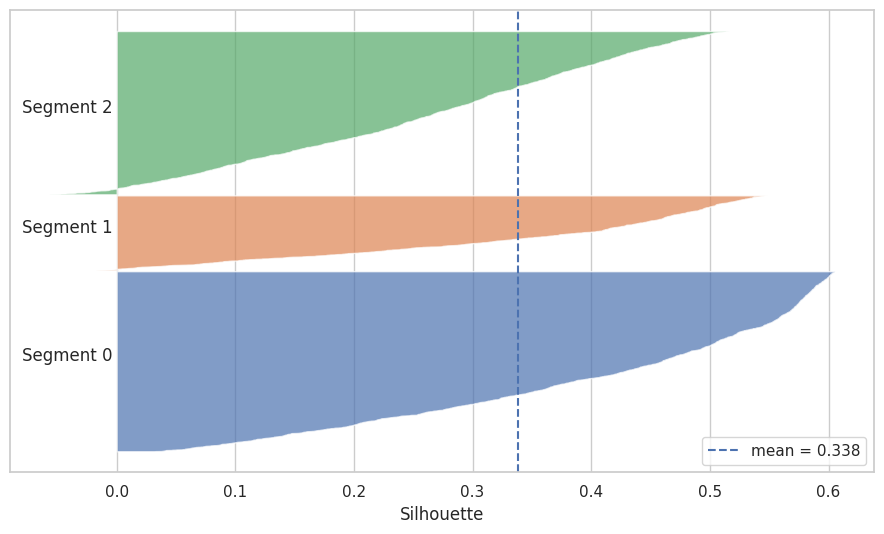

,CustomerID,Recency,Frequency,Monetary,Segment,NearestOtherSegment,Silhouette
2187,15339,67,2,557.5700,2,0,-0.0568
1469,14356,80,2,666.9400,2,0,-0.0566
2143,15275,38,1,609.1900,2,0,-0.0499
3838,17623,33,1,527.0500,2,0,-0.0477
2171,15315,65,2,551.5400,2,0,-0.0473
1460,14346,121,2,"1,021.5800",2,0,-0.0473
2284,15468,52,2,438.4600,2,0,-0.0471
4214,18143,117,2,"1,000.1600",2,0,-0.0429
2868,16268,72,2,617.6500,2,0,-0.0427
2950,16383,75,2,643.7600,2,0,-0.0427


NearestOtherSegment is the numeric ID of the nearest alternative centroid, not a business segment name.


In [ ]:
rfm["Segment"] = final_labels
rfm["Silhouette"] = silhouette_samples(X, final_labels)
distances_to_centres = final_kmeans.transform(X)
nearest_order = np.argsort(distances_to_centres, axis=1)
rfm["NearestOtherSegment"] = [int(cluster_id) for cluster_id in nearest_order[:, 1]]

print("Negative silhouette:", int((rfm.Silhouette < 0).sum()),
      "| below 0.20:", int((rfm.Silhouette < 0.20).sum()),
      f"({(rfm.Silhouette < 0.20).mean():.1%})")

plt.figure(figsize=(9, 5.5))
y_lower = 10
for c in sorted(rfm.Segment.unique()):
    vals = np.sort(rfm.loc[rfm.Segment == c, "Silhouette"].to_numpy())
    plt.fill_betweenx(np.arange(y_lower, y_lower + len(vals)), 0, vals, alpha=0.7)
    plt.text(-0.08, y_lower + len(vals) / 2, f"Segment {c}")
    y_lower += len(vals) + 10
plt.axvline(final_sil, linestyle="--", label=f"mean = {final_sil:.3f}")
plt.xlabel("Silhouette"); plt.yticks([]); plt.legend(); plt.tight_layout(); plt.show()

display(rfm.sort_values("Silhouette").head(15)[
    ["CustomerID", "Recency", "Frequency", "Monetary", "Segment",
     "NearestOtherSegment", "Silhouette"]
])
print("NearestOtherSegment is the numeric ID of the nearest alternative centroid, not a business segment name.")


## 17. Profile and name the clusters

Names are assigned provisionally by ranking **raw RFM medians** across clusters: lower Recency and higher Frequency/Monetary increase the ranking score. The labels are still not ground-truth customer types. Validate them against each cluster's raw medians, means, customer share, and future behaviour. If a name does not match the profile, change the label before making business recommendations.

In [ ]:
name_map = name_segments(rfm[rfm_features], final_labels, FINAL_K)
rfm["SegmentName"] = rfm["Segment"].map(name_map)
order_names = list(name_map.values())

# customers above the clip caps (their Frequency/Monetary were capped before clustering)
hi = final_prep.named_steps["clip"].hi_ if "clip" in final_prep.named_steps else {}
rfm["Capped"] = False
for c, v in hi.items():
    rfm["Capped"] = rfm["Capped"] | (F[:, c] > v)
rfm["Freq1"] = rfm["Frequency"] == 1

profile = rfm.groupby("SegmentName").agg(
    Customers=("CustomerID", "size"),
    Recency_median=("Recency", "median"), Frequency_median=("Frequency", "median"),
    Monetary_median=("Monetary", "median"),
    Recency_mean=("Recency", "mean"), Frequency_mean=("Frequency", "mean"),
    Monetary_mean=("Monetary", "mean"),
    Capped_customers=("Capped", "sum"), Freq1_share=("Freq1", "mean"),
    Revenue=("Monetary", "sum"))
profile["Customer_share_%"] = profile.Customers / profile.Customers.sum() * 100
profile["Revenue_share_%"] = profile.Revenue / profile.Revenue.sum() * 100
profile["Freq1_share_%"] = profile.pop("Freq1_share") * 100
profile = profile.drop(columns="Revenue").loc[order_names]
display(profile.round(2))

n_cap = int(rfm["Capped"].sum())
cap_rev = rfm.loc[rfm["Capped"], "Monetary"].sum() / rfm["Monetary"].sum() * 100
print(f"Customers above clip caps: {n_cap} ({n_cap / len(rfm):.1%} of customers, {cap_rev:.1f}% of revenue)")
print("Caution: revenue share is Monetary by construction (circular). Cell 22 tests it against future behaviour.")

,Customers,Recency_median,Frequency_median,Monetary_median,Recency_mean,Frequency_mean,Monetary_mean,Capped_customers,Customer_share_%,Revenue_share_%,Freq1_share_%
SegmentName,,,,,,,,,,,
Higher Value / Active,773,10.0000,9.0000,"3,491.6400",17.3900,13.2400,"7,286.9600",29,17.8900,68.1100,0.0000
Mid-Tier Customers,1687,30.0000,3.0000,927.8400,44.9100,3.3500,"1,176.3900",0,39.0500,24.0000,8.2400
Lower Value / Less Active,1860,159.5000,1.0000,285.8200,168.2100,1.3400,350.6700,0,43.0600,7.8900,72.8000


Customers above clip caps: 29 (0.7% of customers, 25.3% of revenue)
Caution: revenue share is Monetary by construction (circular). Cell 22 tests it against future behaviour.


## 18. Inspect the highest-scoring segment and capped customers

In [ ]:
# Inspect the highest-ranked segment without assuming it is literally named "Champions".
highest_value_name = order_names[0]
high_value = rfm[rfm.SegmentName == highest_value_name]
print("Highest-scoring provisional segment:", highest_value_name)
display(high_value.groupby("Capped")[rfm_features].median().join(
    high_value.groupby("Capped").size().rename("Customers")))

Highest-scoring provisional segment: Higher Value / Active


,Recency,Frequency,Monetary,Customers
Capped,,,,
False,10.0000,9.0000,"3,408.1300",744
True,4.0000,51.0000,"53,215.7400",29


## 19. Create a separate reporting layer

In [ ]:
# Keep the actual model segment intact; clipping is a separate preprocessing flag.
rfm["ReportSegment"] = rfm["SegmentName"]

report_profile = rfm.groupby("ReportSegment").agg(
    Customers=("CustomerID", "size"),
    Recency_median=("Recency", "median"),
    Frequency_median=("Frequency", "median"),
    Monetary_median=("Monetary", "median"),
    Revenue=("Monetary", "sum")
)
report_profile["Customer_share_%"] = report_profile.Customers / report_profile.Customers.sum() * 100
report_profile["Revenue_share_%"] = report_profile.Revenue / report_profile.Revenue.sum() * 100
display(report_profile.drop(columns="Revenue").round(2).sort_values("Revenue_share_%", ascending=False))

print("Clipping flag counts by actual segment:")
display(rfm.groupby(["SegmentName", "Capped"]).size().unstack(fill_value=0))


,Customers,Recency_median,Frequency_median,Monetary_median,Customer_share_%,Revenue_share_%
ReportSegment,,,,,,
Higher Value / Active,773,10.0000,9.0000,"3,491.6400",17.8900,68.1100
Mid-Tier Customers,1687,30.0000,3.0000,927.8400,39.0500,24.0000
Lower Value / Less Active,1860,159.5000,1.0000,285.8200,43.0600,7.8900


Clipping flag counts by actual segment:


Capped,False,True
SegmentName,,
Higher Value / Active,744,29
Lower Value / Less Active,1860,0
Mid-Tier Customers,1687,0


## 20. Compare segment profiles and feature distributions

,Recent activity,Frequency,Monetary
SegmentName,,,
Higher Value / Active,1.1120,1.6390,1.4030
Mid-Tier Customers,0.3400,0.0990,0.2220
Lower Value / Less Active,-0.7700,-0.7710,-0.7840


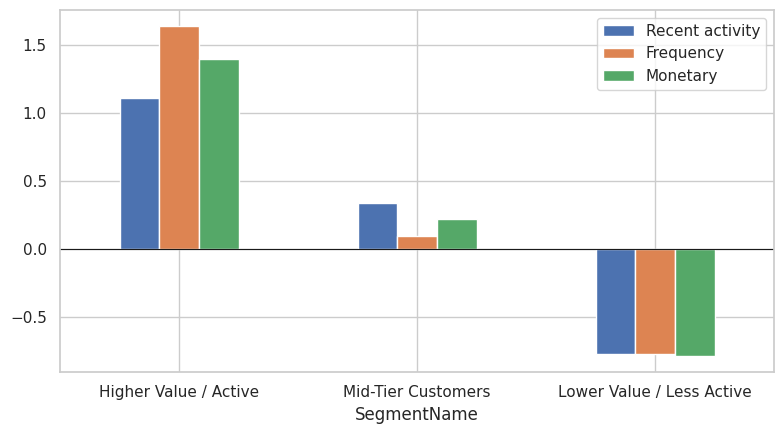

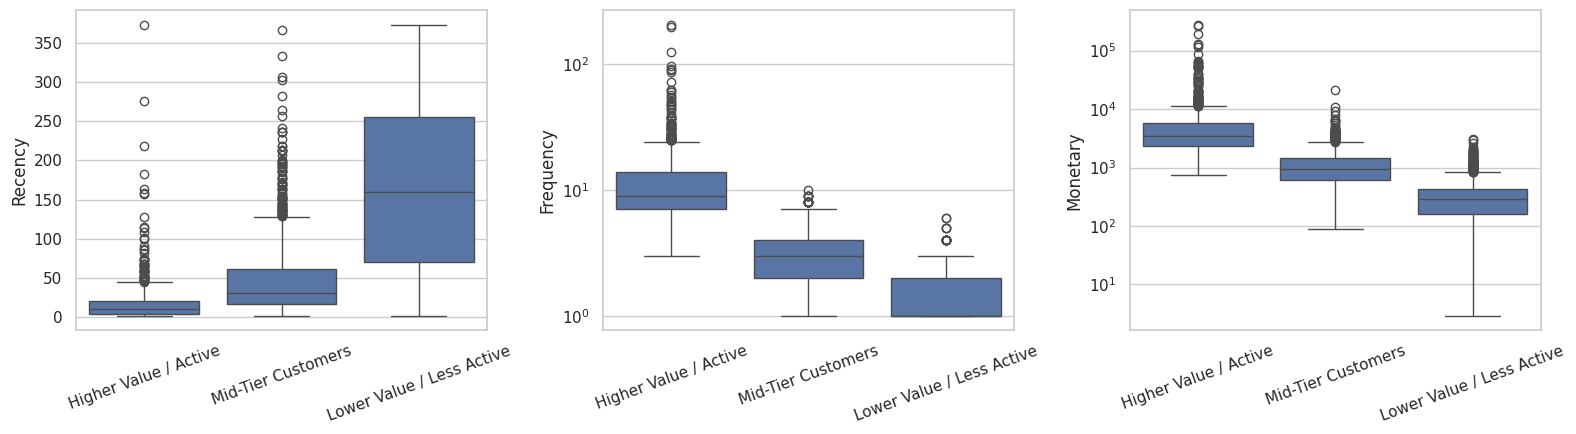

In [ ]:
z_prof = pd.DataFrame(X, columns=["Recency_z", "Frequency_z", "Monetary_z"])
z_prof["SegmentName"] = rfm["SegmentName"].values
z_prof = z_prof.groupby("SegmentName").mean().loc[order_names]
z_prof["Recency_z"] *= -1
z_prof.columns = ["Recent activity", "Frequency", "Monetary"]
display(z_prof.round(3))
z_prof.plot(kind="bar", figsize=(8, 4.5)); plt.axhline(0, color="k", lw=0.8)
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, col in zip(axes, rfm_features):
    sns.boxplot(data=rfm, x="SegmentName", y=col, order=order_names, ax=ax)
    ax.set_yscale("log" if col != "Recency" else "linear"); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()

## 21. Sanity-check segment names

Check whether the highest-scoring segment actually contains recent customers and whether the lowest-scoring segment contains both recently active and inactive customers. These checks are descriptive; do not assume a cluster label alone proves a customer is lapsed.

In [ ]:
highest_value_name = order_names[0]
lowest_value_name = order_names[-1]
print(f"Customers in highest-scoring segment ({highest_value_name}) with Recency > 90 days:",
      int(((rfm.SegmentName == highest_value_name) & (rfm.Recency > 90)).sum()))
print(f"Customers in lowest-scoring segment ({lowest_value_name}) who bought within the last 30 days:",
      int(((rfm.SegmentName == lowest_value_name) & (rfm.Recency <= 30)).sum()))

Customers in highest-scoring segment (Higher Value / Active) with Recency > 90 days: 13
Customers in lowest-scoring segment (Lower Value / Less Active) who bought within the last 30 days: 120


## 22. Visualise clusters with PCA

PCA is a two-dimensional projection for visual inspection. Apparent overlap in 2D does not prove overlap in the full three-dimensional feature space; use silhouette scores as a complementary diagnostic.

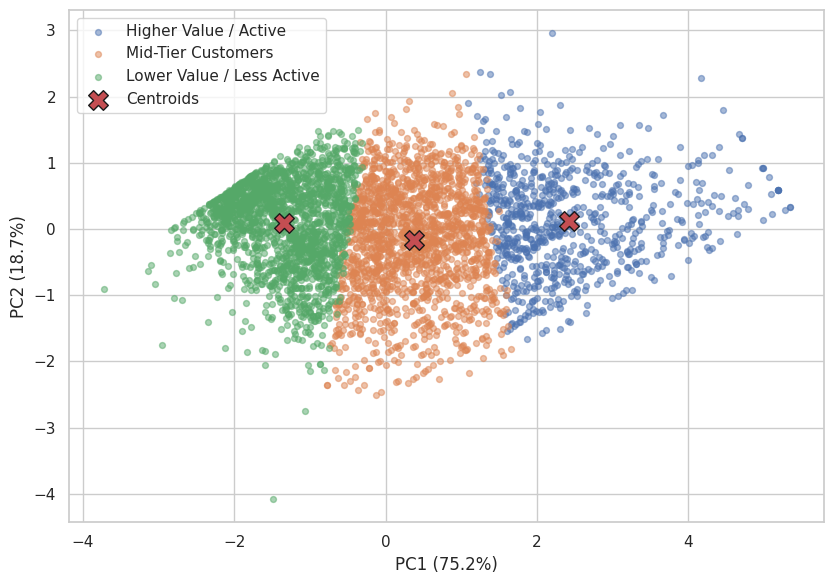

Explained variance, PC1+PC2: 93.9%


In [ ]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X)
cent = pca.transform(final_kmeans.cluster_centers_)

plt.figure(figsize=(8.5, 6))
for seg, name in name_map.items():
    m = final_labels == seg
    plt.scatter(X_pca[m, 0], X_pca[m, 1], s=18, alpha=0.5, label=name)
plt.scatter(cent[:, 0], cent[:, 1], marker="X", s=200, edgecolor="k", label="Centroids")
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%})"); plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%})")
plt.legend(); plt.tight_layout(); plt.show()
print("Explained variance, PC1+PC2:", f"{pca.explained_variance_ratio_.sum():.1%}")

## 23. Time-based validation: repurchase in the following 90 days

Segments are built using data strictly before the cutoff and evaluated on purchases in the following 90 days. This is more realistic than random splitting for future behaviour, but it is still a historical-customer analysis. It does not prove a marketing campaign caused repurchases, and seasonality or the choice of cutoff can affect results.

In [ ]:
cutoff = snapshot_date - pd.Timedelta(days=90)
df_early = df.loc[df["InvoiceDate"] < cutoff].copy()
df_late = df.loc[(df["InvoiceDate"] >= cutoff) & (~df["IsCancellation"])].copy()
if df_early.empty:
    raise ValueError("The early period is empty; cannot perform 90-day time-based validation.")
if df_late.empty:
    warnings.warn("No non-cancellation transactions exist in the 90-day evaluation window; repurchase rates will be zero.")

rfm_e = build_rfm(df_early, cutoff)
rfm_e["Monetary"] = rfm_e["Monetary"].round(2)
rfm_e = rfm_e.loc[rfm_e["Monetary"] > 0].reset_index(drop=True)

F_e = np.log1p(rfm_e[rfm_features].to_numpy(dtype=float))
prep_e = make_preprocessor().fit(F_e)
X_e = prep_e.transform(F_e)

future = df_late.groupby("CustomerID").agg(FutureInvoices=("InvoiceNo", "nunique"),
                                           FutureSpend=("TotalPrice", "sum"))
base = rfm_e.merge(future, on="CustomerID", how="left").fillna({"FutureInvoices": 0, "FutureSpend": 0})
base["Repurchased"] = base["FutureInvoices"] > 0

print(f"Customers in early window: {len(base):,} | overall repurchase rate: {base.Repurchased.mean():.1%}")
print("Segments built on data before", cutoff.date(), "and judged on the following 90 days.\n")

retention_tables = {}
for k in sorted(set([2, FINAL_K])):
    km_e = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=20).fit(X_e)
    nm = name_segments(rfm_e[rfm_features], km_e.labels_, k)
    tmp = base.copy()
    tmp["SegmentName"] = pd.Series(km_e.labels_).map(nm).values
    tab = tmp.groupby("SegmentName").agg(
        Customers=("CustomerID", "size"),
        Repurchase_rate=("Repurchased", "mean"),
        Mean_future_spend=("FutureSpend", "mean"),
        Median_future_spend=("FutureSpend", "median")).loc[list(nm.values())]
    retention_tables[k] = tab
    print(f"k={k}")
    display(tab)

retention_check = retention_tables[FINAL_K]

Customers in early window: 3,359 | overall repurchase rate: 57.0%
Segments built on data before 2011-09-11 and judged on the following 90 days.

k=2


,Customers,Repurchase_rate,Mean_future_spend,Median_future_spend
SegmentName,,,,
Active / Higher Value,1197,0.8087,"1,744.8716",684.2400
Less Active / Lower Value,2162,0.4385,326.1080,0.0000


k=3


,Customers,Repurchase_rate,Mean_future_spend,Median_future_spend
SegmentName,,,,
Higher Value / Active,542,0.9133,"3,004.2278","1,218.9250"
Mid-Tier Customers,1270,0.6551,542.5617,278.5050
Lower Value / Less Active,1547,0.3807,307.8940,0.0000


## 24. Export reproducible outputs

CSV files are written to the current notebook working directory. The customer export includes `LapsedRiskFlag`, defined by an explicit Recency threshold, instead of the previous incorrectly oriented `RecentLapsed` flag. Review the generated files after a successful full run.

In [ ]:
# Final reporting outputs (safe to re-run)
rfm["ReportSegment"] = rfm["SegmentName"]

# A customer is flagged as at risk of lapse only when their last purchase is
# older than the explicitly chosen threshold. This is a heuristic, not a
# universal definition; adapt the threshold to the business purchase cycle.
LAPSED_RECENCY_DAYS = 90
LOWEST_VALUE_SEGMENT_ONLY = False
rfm["LapsedRiskFlag"] = rfm["Recency"] > LAPSED_RECENCY_DAYS
if LOWEST_VALUE_SEGMENT_ONLY:
    lowest_value_name = order_names[-1]
    rfm["LapsedRiskFlag"] = rfm["LapsedRiskFlag"] & (rfm["SegmentName"] == lowest_value_name)
print(f"Lapsed-risk threshold: Recency > {LAPSED_RECENCY_DAYS} days")
print("Customers flagged at lapse risk:", int(rfm["LapsedRiskFlag"].sum()))

report_profile = rfm.groupby("ReportSegment").agg(
    Customers=("CustomerID", "size"),
    Recency_median=("Recency", "median"),
    Frequency_median=("Frequency", "median"),
    Monetary_median=("Monetary", "median"),
    Revenue=("Monetary", "sum")
)
report_profile["Customer_share_%"] = report_profile.Customers / report_profile.Customers.sum() * 100
report_profile["Revenue_share_%"] = report_profile.Revenue / report_profile.Revenue.sum() * 100
report_profile = report_profile.drop(columns="Revenue").sort_values("Revenue_share_%", ascending=False)

retention_both = pd.concat({f"k={k}": t for k, t in retention_tables.items()}, names=["Model", "Segment"])

outputs = {
    "final_customer_segments.csv": rfm,
    "model_comparison_equal_k.csv": model_comparison,
    "k_selection_decision_table.csv": sel,
    "bootstrap_stability.csv": bootstrap_df,
    "segment_profile.csv": profile.reset_index(),
    "report_segment_profile.csv": report_profile.reset_index(),
    "retention_time_split_check.csv": retention_both.reset_index(),
    "cleaning_log.csv": cleaning_log_df,
    "customer_loss_log.csv": customer_loss_log,
}
for name, frame in outputs.items():
    frame.to_csv(name, index=False)
    print("Saved:", name)


Lapsed-risk threshold: Recency > 90 days
Customers flagged at lapse risk: 1443
Saved: final_customer_segments.csv
Saved: model_comparison_equal_k.csv
Saved: k_selection_decision_table.csv
Saved: bootstrap_stability.csv
Saved: segment_profile.csv
Saved: report_segment_profile.csv
Saved: retention_time_split_check.csv
Saved: cleaning_log.csv
Saved: customer_loss_log.csv


In [ ]:
# Export the manually selected model, portable parameters, and evaluation reports.
# The exported sklearn pipeline accepts RAW RFM values in this order:
# Recency, Frequency, Monetary. It applies log1p, fitted clipping/scaling, then K-Means.

import os, json, shutil, joblib
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer

EXPORT_DIR = "model_export"
os.makedirs(EXPORT_DIR, exist_ok=True)

# 1. Deployable sklearn pipeline: no refitting happens in this cell.
model_pipeline = Pipeline(steps=[
    ("log1p", FunctionTransformer(np.log1p, validate=False, feature_names_out="one-to-one")),
    ("preprocess", final_prep),
    ("kmeans", final_kmeans),
])

model_bundle = {
    "pipeline": model_pipeline,
    "feature_names": list(rfm_features),
    "cluster_name_map": {int(k): str(v) for k, v in name_map.items()},
    "final_k": int(FINAL_K),
    "random_state": int(RANDOM_STATE),
    "snapshot_date": str(pd.Timestamp(snapshot_date).date()),
    "lapsed_recency_threshold_days": 90,
    "model_type": "KMeans",
    "input_contract": {
        "columns_in_order": list(rfm_features),
        "values": "RAW Recency, Frequency, Monetary; do not log-transform before prediction",
        "definitions": {
            "Recency": "Days between snapshot date and customer's latest purchase invoice date",
            "Frequency": "Number of distinct non-cancellation purchase invoices",
            "Monetary": "Net transaction value including cancellation rows, rounded to 2 decimal places"
        }
    },
    "notes": "Joblib pipeline includes log1p, fitted clipping/scaling, and K-Means."
}

joblib_path = os.path.join(EXPORT_DIR, "customer_segmentation_model.joblib")
joblib.dump(model_bundle, joblib_path)

# Reload test: exported pipeline must reproduce the fitted cluster IDs.
reloaded_bundle = joblib.load(joblib_path)
raw_rfm = rfm[rfm_features].to_numpy(dtype=float)
sample_n = min(100, len(raw_rfm))
export_labels = reloaded_bundle["pipeline"].predict(raw_rfm[:sample_n])
assert np.array_equal(export_labels, final_kmeans.labels_[:sample_n]), (
    "Reloaded pipeline predictions do not match final K-Means labels on the sample."
)
print("Joblib reload check passed on", sample_n, "raw-RFM customers.")

# 2. Portable JSON parameters for implementing inference without the custom Winsorizer class.
clipper = final_prep.named_steps.get("clip")
scaler = final_prep.named_steps["scale"]
clip_upper_log = {}
if clipper is not None:
    clip_upper_log = {
        rfm_features[int(col)]: float(limit)
        for col, limit in clipper.hi_.items()
    }

portable_params = {
    "algorithm": "KMeans",
    "final_k": int(FINAL_K),
    "random_state": int(RANDOM_STATE),
    "features": list(rfm_features),
    "input_contract": "Raw Recency, Frequency, Monetary. Apply natural log1p first.",
    "clip_quantile": CLIP_Q,
    "clip_upper_log_scale": clip_upper_log,
    "scaler_mean": scaler.mean_.astype(float).tolist(),
    "scaler_scale": scaler.scale_.astype(float).tolist(),
    "centroids_scaled": final_kmeans.cluster_centers_.astype(float).tolist(),
    "segment_names": {str(k): str(v) for k, v in name_map.items()},
    "snapshot_date": str(pd.Timestamp(snapshot_date).date()),
    "lapsed_recency_threshold_days": 90,
    "customers_modelled": int(len(rfm)),
    "note": "JSON parameters are for portable inference. See the input contract for required RFM definitions."
}
params_path = os.path.join(EXPORT_DIR, "final_model_params.json")
with open(params_path, "w", encoding="utf-8") as f:
    json.dump(portable_params, f, indent=2)

# 3. Save final evaluation tables with a clear distinction between in-sample and held-out metrics.
boot_rows = bootstrap_df.loc[bootstrap_df["k"] == FINAL_K]
boot = boot_rows.iloc[0] if not boot_rows.empty else None
n_neg = int((rfm["Silhouette"] < 0).sum())
n_low = int((rfm["Silhouette"] < 0.20).sum())

evaluation_rows = [
    ("Algorithm", "K-Means", ""),
    ("Final K (manually chosen)", FINAL_K, "Chosen by user after reviewing evaluation evidence"),
    ("Customers modelled", len(rfm), ""),
    ("Silhouette (full data)", final_sil, "In-sample descriptive metric"),
    ("Davies-Bouldin (full data)", final_db, "In-sample; lower is better"),
    ("Calinski-Harabasz (full data)", final_ch, "In-sample; compare on same dataset"),
    ("Silhouette (train 70%)", chosen["sil_train"], "Preprocessing fitted on train only"),
    ("Silhouette (validation 30%)", chosen["sil_test"], "Used during K selection; not an independent final test"),
    ("Davies-Bouldin (validation 30%)", chosen["db_test"], "Used during K selection; not an independent final test"),
    ("Prediction strength mean", chosen["ps_mean"], "Random half-splits; mean of valid repeats"),
    ("Prediction strength SD", chosen["ps_std"], ""),
    ("Prediction strength minimum", chosen["ps_min"], "May be below threshold even when mean passes"),
    ("Prediction strength maximum", chosen["ps_max"], ""),
    ("Valid prediction-strength repeats", chosen["valid_splits"], "Out of 15 requested repeats"),
    ("Bootstrap ARI mean", boot["ARI_mean"] if boot is not None else np.nan,
     "Resampling stability; not independent test accuracy"),
    ("Bootstrap ARI SD", boot["ARI_std"] if boot is not None else np.nan, ""),
    ("Bootstrap ARI minimum", boot["ARI_min"] if boot is not None else np.nan, ""),
    ("Customers with negative silhouette", n_neg, f"{n_neg / len(rfm):.1%} of customers"),
    ("Customers with silhouette below 0.20", n_low, f"{n_low / len(rfm):.1%} of customers"),
]
final_model_evaluation = pd.DataFrame(evaluation_rows, columns=["Metric", "Value", "Note"])

seg_eval = rfm.groupby("SegmentName").agg(
    Customers=("CustomerID", "size"),
    Mean_silhouette=("Silhouette", "mean"),
    Negative_silhouette=("Silhouette", lambda s: int((s < 0).sum())),
    Below_0_20=("Silhouette", lambda s: int((s < 0.20).sum()))
)
seg_eval["Share_below_0.20_%"] = seg_eval["Below_0_20"] / seg_eval["Customers"] * 100

final_model_evaluation.to_csv(os.path.join(EXPORT_DIR, "final_model_evaluation.csv"), index=False)
seg_eval.reset_index().to_csv(os.path.join(EXPORT_DIR, "final_model_by_segment.csv"), index=False)
if FINAL_K in retention_tables:
    retention_tables[FINAL_K].reset_index().to_csv(
        os.path.join(EXPORT_DIR, "final_model_retention_check.csv"), index=False
    )
rfm.to_csv(os.path.join(EXPORT_DIR, "final_customer_segments.csv"), index=False)
sel.to_csv(os.path.join(EXPORT_DIR, "k_selection_decision_table.csv"), index=False)
profile.reset_index().to_csv(os.path.join(EXPORT_DIR, "segment_profile.csv"), index=False)

display(final_model_evaluation)
display(seg_eval.round(4))

zip_path = shutil.make_archive("final_model_export", "zip", EXPORT_DIR)
print("Created:", zip_path)
print("Contains:", sorted(os.listdir(EXPORT_DIR)))
try:
    from google.colab import files
    files.download(zip_path)
except ImportError:
    print("Outside Colab: find the ZIP in the notebook working directory.")


Joblib reload check passed on 100 raw-RFM customers.


,Metric,Value,Note
0,Algorithm,K-Means,
1,Final K (manually chosen),3,Chosen by user after reviewing evaluation evid...
2,Customers modelled,4320,
3,Silhouette (full data),0.3384,In-sample descriptive metric
4,Davies-Bouldin (full data),1.0429,In-sample; lower is better
5,Calinski-Harabasz (full data),"3,719.9810",In-sample; compare on same dataset
6,Silhouette (train 70%),0.3336,Preprocessing fitted on train only
7,Silhouette (validation 30%),0.3347,Used during K selection; not an independent fi...
8,Davies-Bouldin (validation 30%),1.0403,Used during K selection; not an independent fi...
9,Prediction strength mean,0.8676,Random half-splits; mean of valid repeats


,Customers,Mean_silhouette,Negative_silhouette,Below_0_20,Share_below_0.20_%
SegmentName,,,,,
Higher Value / Active,773,0.3379,13,178,23.0272
Lower Value / Less Active,1860,0.4113,0,273,14.6774
Mid-Tier Customers,1687,0.2582,61,590,34.9733


Created: /content/final_model_export.zip
Contains: ['customer_segmentation_model.joblib', 'final_customer_segments.csv', 'final_model_by_segment.csv', 'final_model_evaluation.csv', 'final_model_params.json', 'final_model_retention_check.csv', 'k_selection_decision_table.csv', 'segment_profile.csv']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>